# Machine learning

## Practice Task 2. Exploratory Data Analysis and Linear Regression

### General information
Date of issue: 

Soft deadline: 

Hard Deadline: 

### About the job
In this task, we will try to learn how to analyze data and select useful features from them. We'll also learn how to use ``seaborn`` and ``sklearn``, while also getting used to the basic concepts of machine learning.

### Evaluation and Penalties
Each of the tasks has a certain "cost" (indicated in parentheses near the task). The maximum allowable grade for a job is 10 points. The reviewer has the right to lower the grade for ineffective implementation or sloppy schedules.

**Please note** that each section of the homework has grading problems and questions. Questions complement the objectives and aim to interpret or justify what is happening. The code without interpretation does not make sense, therefore it is obligatory to answer the questions - for the absence of answers, we will reduce the points for the tasks. If you answer the questions, but do not write the correct code for the corresponding graded problems, then no points will be awarded for that.

You cannot hand over the task after the specified deadline. If an incomplete point is given for a task due to errors, at the discretion of the examiner, it is possible to correct the work on the conditions specified in the response letter.

The task is carried out independently. "Similar" solutions are considered plagiarism and all involved students (including those who were cheated) cannot receive more than 0 points for it (for more information on plagiarism, see the course page). If you have found a solution to some of the tasks (or part of it) in an open source, you must provide a link to this source in a separate block at the end of your work (most likely you will not be the only one who found this, therefore, in order to exclude suspicion of plagiarism, a link to the source is required).

### Change format
Tasks are submitted through the EDUFPMI-portal in the assignments section.  You must send a notebook with a completed assignment. Name the notebook itself in the format homework-practice-02-linregr-Username.ipynb, where Username is your last name.

For the convenience of checking, independently calculate your maximum score (based on the set of solved problems) and indicate below.

Rating: 13. 

This notebook uses the ``folium`` library to render maps. She works for google colab! 

In [2]:
import folium
# folium is already available in this environment, so the pip call is not needed.
# %pip install -q folium

In [3]:
m = folium.Map(location=(53.9000000, 27.5666700), zoom_start=12)
m.get_root().height = 480
m

If you did everything correctly, then a map of Minsk should open above. .

*Find the coordinates of the place of your study and show on the map*

In [4]:
# BSU main building (Haloŭny korpus BDU), 4 Independence Ave. (prasp. Niezaliežnasci 4),
# Minsk - the building where the FPMI classes take place. Coordinates taken from the OSM
# object "Галоўны корпус БДУ" (building, house number 4).
bsu_location = (53.893898, 27.546963)

m = folium.Map(location=bsu_location, zoom_start=16)
folium.Marker(
    location=bsu_location,
    popup="Belarusian State University",
    tooltip="Place of study",
    icon=folium.Icon(color="red", icon="info-sign"),
).add_to(m)
m.get_root().height = 480
m

**Note**: ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ - the place for your code and/or your answers (this smile is from http://lenny.club/magic/)

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set(style="darkgrid")

## Part 0. Preparation (1 point) 

**Task 1 (1 point)**. We will be working with data from the competition [New York City Taxi Trip Duration](https://www.kaggle.com/c/nyc-taxi-trip-duration/overview), in which it was necessary to predict the duration of a taxi trip. Download the training sample from this competition and upload it:

In [6]:
%%time
train_data = pd.read_csv("train.csv", parse_dates=["pickup_datetime"])
test_data = pd.read_csv("test.csv", parse_dates=["pickup_datetime"])

print("train:", train_data.shape)
print("test: ", test_data.shape)

train: (1458644, 11)
test:  (625134, 9)
CPU times: user 2.6 s, sys: 1.14 s, total: 3.74 s
Wall time: 3.18 s


In [7]:
train_data.head()

,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


In [8]:
test_data.head()

,id,vendor_id,pickup_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag
0,id3004672,1,2016-06-30 23:59:58,1,-73.988129,40.732029,-73.990173,40.756680,N
1,id3505355,1,2016-06-30 23:59:53,1,-73.964203,40.679993,-73.959808,40.655403,N
2,id1217141,1,2016-06-30 23:59:47,1,-73.997437,40.737583,-73.986160,40.729523,N
3,id2150126,2,2016-06-30 23:59:41,1,-73.956070,40.771900,-73.986427,40.730469,N
4,id1598245,1,2016-06-30 23:59:33,1,-73.970215,40.761475,-73.961510,40.755890,N


In [9]:
train_data.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'dropoff_datetime',
       'passenger_count', 'pickup_longitude', 'pickup_latitude',
       'dropoff_longitude', 'dropoff_latitude', 'store_and_fwd_flag',
       'trip_duration'],
      dtype='str')

In [10]:
test_data.columns

Index(['id', 'vendor_id', 'pickup_datetime', 'passenger_count',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude',
       'dropoff_latitude', 'store_and_fwd_flag'],
      dtype='str')

Notice the ``pickup_datetime`` and ``dropoff_datetime columns``. The columm ``dropoff_datetime`` was added by the organizers only to the training set, that is, this column cannot be used, let's remove it. The ``pickup_datetime`` contains the date and time of the start of the trip. To make it convenient to work with it, let's convert dates to ``datetime`` objects. 


In [11]:
train_data.drop('dropoff_datetime',
  axis='columns', inplace=True)

In [12]:
train_data['pickup_datetime'] =  pd.to_datetime(train_data['pickup_datetime'])
test_data['pickup_datetime'] =  pd.to_datetime(test_data['pickup_datetime'])

In [13]:
print("dtype of pickup_datetime:", train_data["pickup_datetime"].dtype)
print("period:", train_data["pickup_datetime"].min(), "->", train_data["pickup_datetime"].max())

dtype of pickup_datetime: datetime64[us]
period: 2016-01-01 00:00:17 -> 2016-06-30 23:59:39


The ``trip_duration`` column contains the target value that we want to predict. Let's take a look at the distribution of the target in the training set. Draw two histograms: the full range with log-spaced bins (left), and the body under one hour with the mean and the median marked (right):


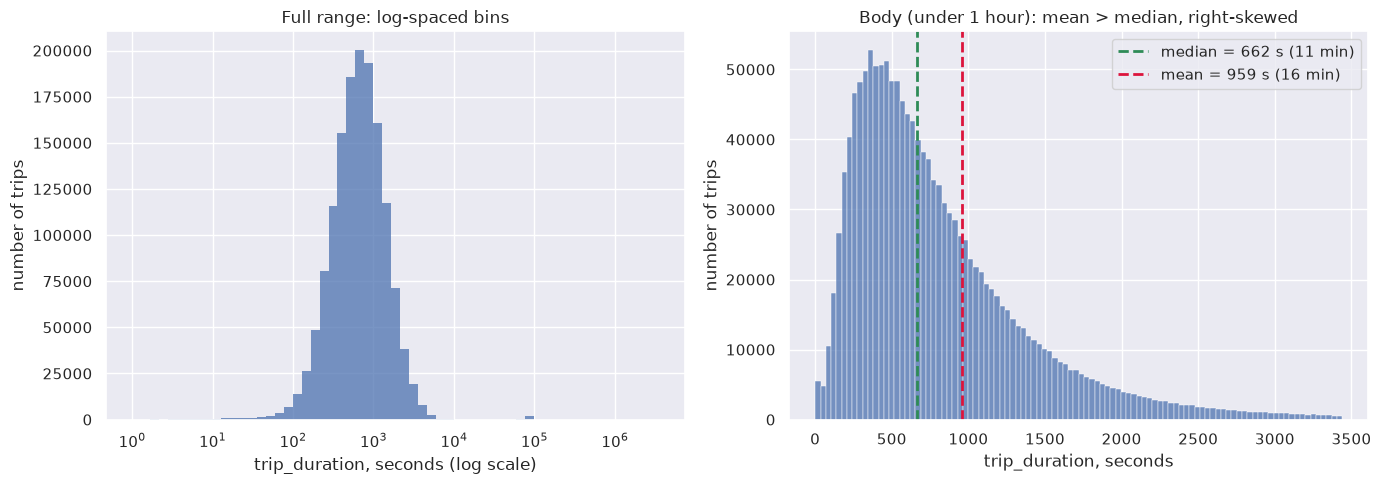

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: the full range needs log-spaced bins, otherwise 99.9% of the trips
# would fall into the first equal-width bin
bins = np.logspace(0, np.log10(train_data["trip_duration"].max()), 60)
sns.histplot(train_data["trip_duration"], bins=bins, ax=axes[0])
axes[0].set_xscale("log")
axes[0].set_xlabel("trip_duration, seconds (log scale)")
axes[0].set_ylabel("number of trips")
axes[0].set_title("Full range: log-spaced bins")

# right: the body (under one hour) on a linear scale, with the mean and the
# median marked - the mean sits to the right of the median because of the tail
body = train_data.loc[train_data["trip_duration"] < 3440, "trip_duration"]
sns.histplot(body, bins=100, ax=axes[1])
median = train_data["trip_duration"].median()
mean = train_data["trip_duration"].mean()
axes[1].axvline(median, color="seagreen", linestyle="--", linewidth=2,
                label="median = %.0f s (%.0f min)" % (median, median / 60))
axes[1].axvline(mean, color="crimson", linestyle="--", linewidth=2,
                label="mean = %.0f s (%.0f min)" % (mean, mean / 60))
axes[1].set_xlabel("trip_duration, seconds")
axes[1].set_ylabel("number of trips")
axes[1].set_title("Body (under 1 hour): mean > median, right-skewed")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


**Question**: *What can be said about the target variable from the histogram of its values*?

**Answer.** The target is strongly right-skewed: its shape in log space is close to a bell, so the durations are roughly *log-normal* rather than arbitrarily skewed.

The left histogram needs a log axis with log-spaced bins because the values span six and a half orders of magnitude, from 1 s to 3 526 282 s (about 41 days, 979 h). Nearly all of the mass lies between 10^2 and 3×10^3 s; the few isolated bars at 10^5–10^6 s are single rides that lasted many hours, and with equal-width bins the whole picture would collapse into a single bar.

The right histogram zooms into the body — the 99% of trips shorter than 3440 s — and shows the classic right-skewed profile: a mode just under 7 min (400–450 s), a steep left flank and a long, slowly decaying tail. The quartiles make this concrete — 397 s, 662 s and 1075 s (6.6, 11 and 18 min) — while the arithmetic mean is 959 s (16 min), i.e. 45% above the median. The distance between the two dashed lines *is* the pull of the tail; note that both statistics are computed on the whole training set, whereas the panel is truncated at one hour only for readability.

Two consequences for modelling follow. Fitting raw seconds by least squares is a bad idea: one multi-day ride produces an error orders of magnitude larger than an ordinary one and takes over the objective. And because log(y + 1) is nearly symmetric, the natural scale of the problem is the *relative* error — which is exactly why the competition metric is RMSLE and why we fit the logarithm of the target.

In [15]:
train_data['trip_duration'].quantile([0.25,0.5,0.75,0.99, 1])

0.25        397.0
0.50        662.0
0.75       1075.0
0.99       3440.0
1.00    3526282.0
Name: trip_duration, dtype: float64

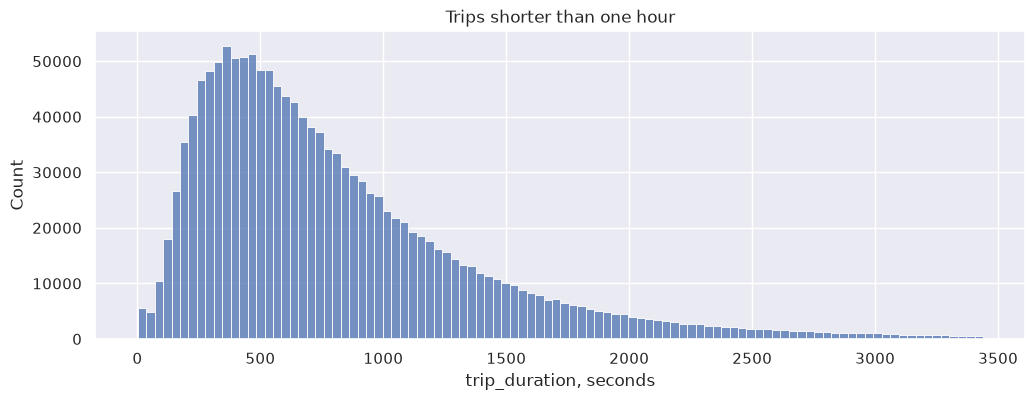

In [16]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.histplot(train_data.loc[train_data["trip_duration"] < 3440, "trip_duration"], bins=100, ax=ax)
ax.set_xlabel("trip_duration, seconds")
ax.set_title("Trips shorter than one hour")
plt.show()

In the competition, the quality metric was RMSLE:
$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell} \big(\log{(y_i + 1)} - \log{(a(x_i) + 1)}\big)^2}$$

**Question**: *Why do you think the authors of the competition chose RMSLE and not RMSE?*

**Answer.** RMSLE compares relative errors: a 10 % mistake on a 3-minute ride and on a
3-hour ride is penalised equally, while RMSE in seconds would be dominated by the few very
long trips. The competition is about predicting how long a trip takes in relative terms
(and the leaderboard would otherwise be decided by a dozen outliers).

There are several linear regression models in ``sklearn``, but each optimizes mean squared error (MSE) rather than RMSLE. Let's do the following trick: we will not predict the target variable, but its *logarithm*. Denote $\hat{y}_i = \log{(y_i + 1)}$ — modified target, а $\hat{a}(x_i)$ — model forecast, trained on $\hat{y}_i$, that is logarithm of target. To predict the original value, we can simply take the exponent from our prediction: $a(x_i) = \exp(\hat{a}(x_i)) - 1$.

**Question**: Show that RMSLE optimization for model $a$ is equivalent to MSE optimization for model  $\hat{a}$.

**Proof**: ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

So, we were able to reduce the RMSLE optimization problem to an MSE optimization problem that we know how to solve! In addition, the target logarithm has another useful property. To see it, add the column ``log_trip_duration`` to our sample (use ``np.log1p``) and draw a histogram of the modified target for the training sample. Delete the column with the old target. 

**Proof.** Denote $\hat{y}_i = \log(y_i + 1)$，$\hat{a}(x_i) = \log(a(x_i) + 1)$.
Then

$$\text{RMSLE}(X, y, a) = \sqrt{\frac{1}{\ell}\sum_{i=1}^{\ell}\big(\hat{y}_i - \hat{a}(x_i)\big)^2} = \text{RMSE}(\hat{y}, \hat{a})$$

So minimising MSE over the model $\\hat{a}$ trained on the log target is *exactly* minimising
RMSLE over the model $a$ trained on the original target: the monotone transform does not
change the minimiser, only the units in which the error is measured. $\\blacksquare$

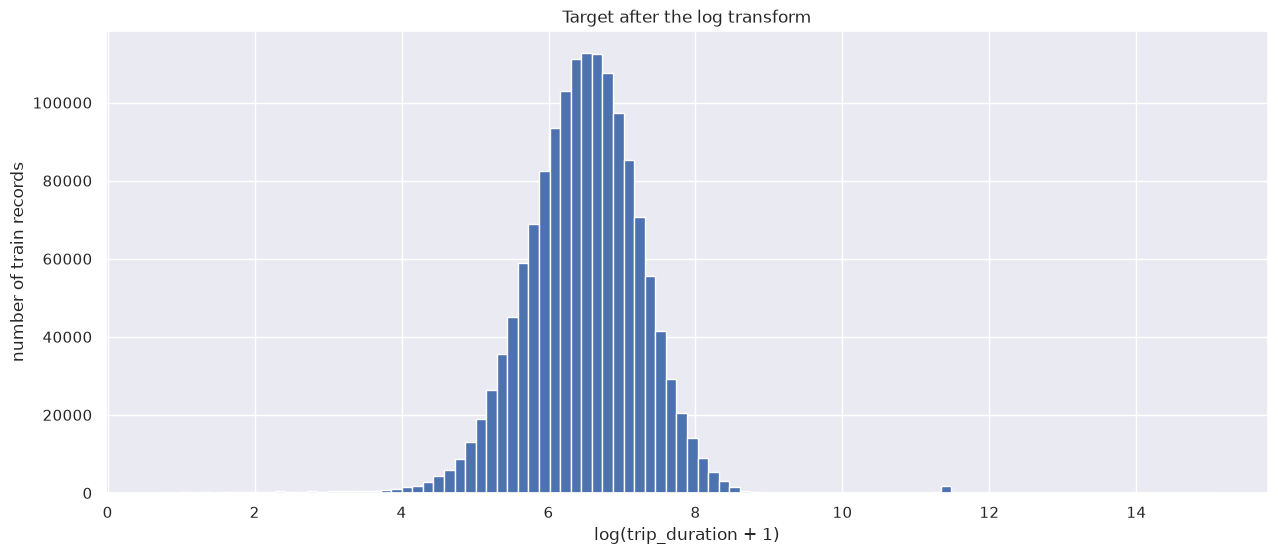

CPU times: user 135 ms, sys: 3.94 ms, total: 139 ms
Wall time: 140 ms


In [17]:
%%time
train_data["log_trip_duration"] = np.log1p(train_data["trip_duration"].values)

plt.figure(figsize=(15, 6))
plt.hist(train_data["log_trip_duration"].values, bins=100)
plt.xlabel("log(trip_duration + 1)")
plt.ylabel("number of train records")
plt.title("Target after the log transform")
plt.show()

To have some point of reference, let's calculate the value of the metric at the best constant prediction :

In [18]:
# the best constant prediction is the mean of the log target
const_pred = train_data["log_trip_duration"].mean()
const_rmsle = np.sqrt(np.mean((train_data["log_trip_duration"] - const_pred) ** 2))

print(f"constant prediction, log space : {const_pred:.4f}")
print(f"constant prediction, seconds   : {np.expm1(const_pred):.1f}")
print(f"RMSLE of the constant model    : {const_rmsle:.4f}")

constant prediction, log space : 6.4670
constant prediction, seconds   : 642.5
RMSLE of the constant model    : 0.7958


In [19]:
# longest trip in hours
train_data['trip_duration'].max() // 3600 

np.int64(979)

## Part 1. Learn `pickup_datetime` (2 points)

**Task 2 (0.25 points)**. First, let's see how many trips there were on each of the days. Build a graph of the dependence of the number of trips on the day of the year (for example, you can use  `sns.countplot`):

In [20]:
from datetime import datetime

In [21]:
train_data['dow'] = train_data.pickup_datetime.dt.dayofweek
train_data['month'] = train_data.pickup_datetime.dt.month
train_data['hour'] = train_data.pickup_datetime.dt.hour
train_data['doy'] = train_data.pickup_datetime.dt.dayofyear

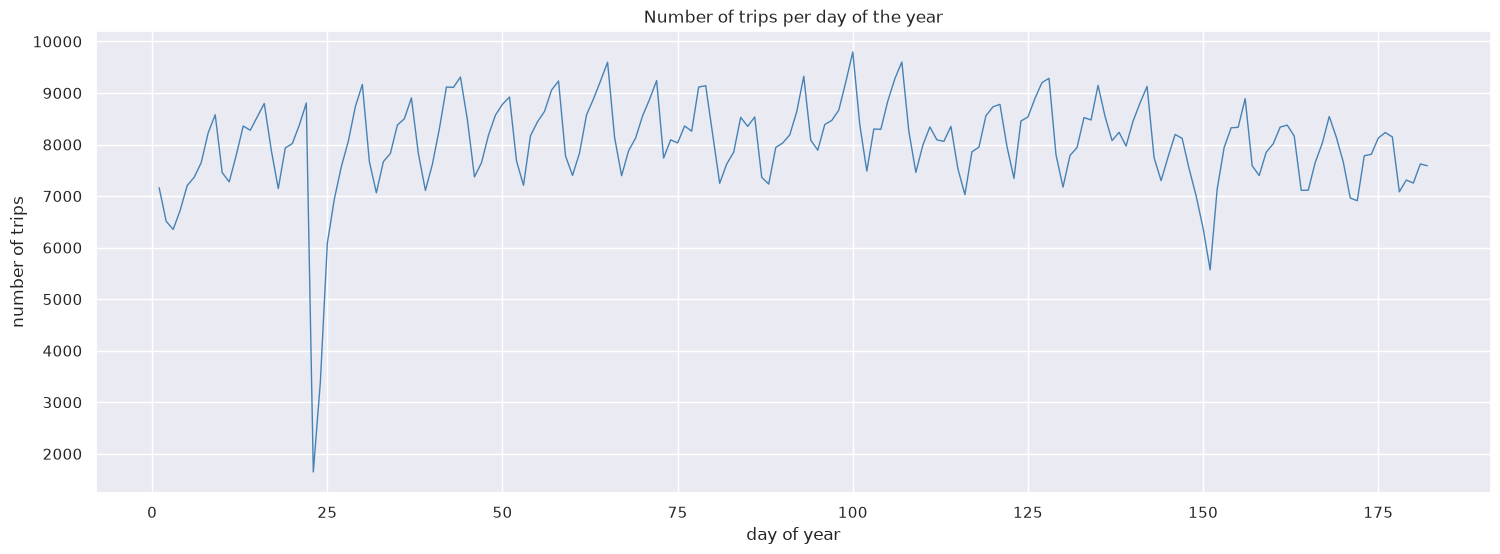

five days with the fewest trips:
doy
23     1648
24     3383
151    5570
25     6084
3      6353
dtype: int64


In [22]:
by_doy = train_data.groupby("doy").size()

fig, ax = plt.subplots(figsize=(18, 6))
ax.plot(by_doy.index, by_doy.values, lw=1, color="steelblue")
ax.set_xlabel("day of year")
ax.set_ylabel("number of trips")
ax.set_title("Number of trips per day of the year")
plt.show()

print("five days with the fewest trips:")
print(by_doy.nsmallest(5))

**Question**: You have probably noticed that there are 2 periods on the graph with abnormally small amounts of trips. Calculate on what dates these downward jumps took place and find information about what was happening in New York these days.

Draw graphs of the dependence of the number of trips on the day of the week and on the hours per day (use  `sns.relplot`):

**Answer.** The two gaps are January 23-24 and May 29-30, 2016.

* **January 23-24** — Winter Storm Jonas: New York declared a state of emergency, the roads
  were closed to non-emergency traffic, and the number of trips collapsed from about 8,000 a
  day to 1,648 (23 January) and 3,383 (24 January), a drop of nearly 80 %.
* **May 29-30** — the Memorial Day long weekend (Monday 30 May was the holiday itself). The
  commuting demand disappears: 6,372 and 5,570 trips instead of the usual 8,000.

Both drops are about the calendar and not about the taxi system, which is why they are kept
as two separate flags rather than one.

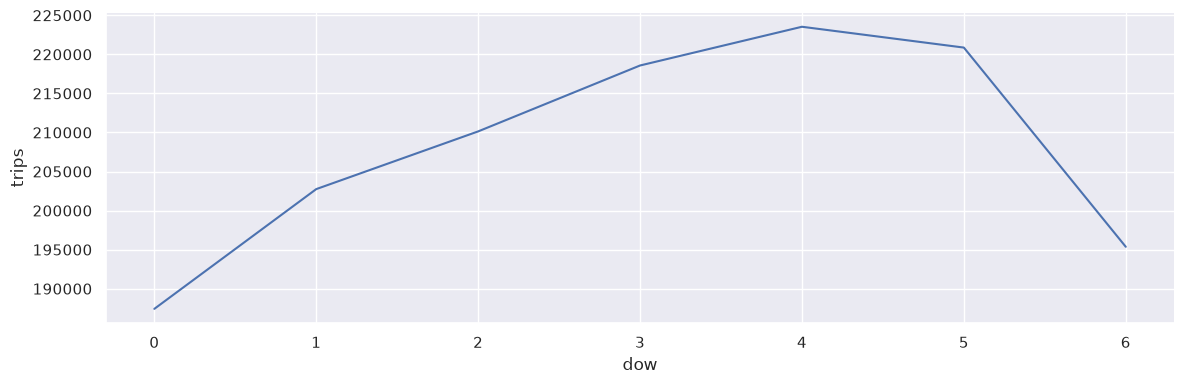

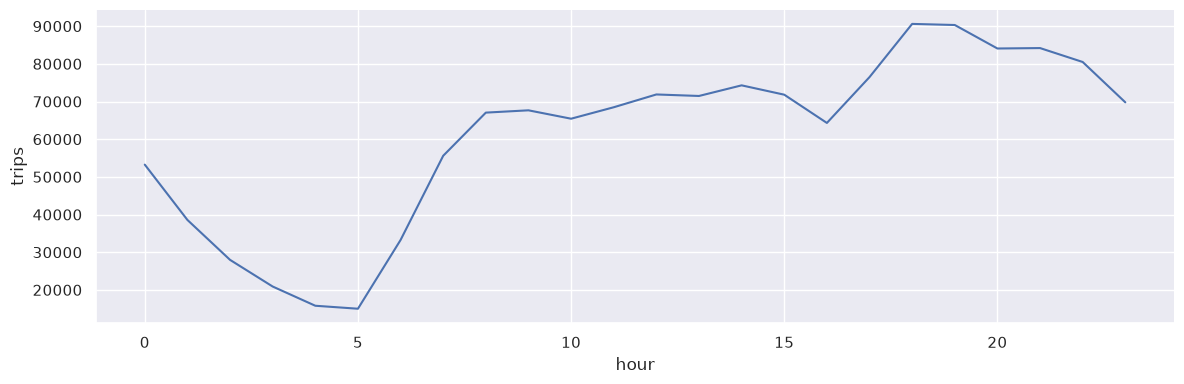

In [23]:
by_dow = train_data.groupby("dow").size().reset_index(name="trips")
by_hour = train_data.groupby("hour").size().reset_index(name="trips")

sns.relplot(data=by_dow, x="dow", y="trips", kind="line", height=4, aspect=3)
sns.relplot(data=by_hour, x="hour", y="trips", kind="line", height=4, aspect=3)
plt.show()

In [24]:
grouped = train_data.groupby("doy").size().reset_index(name="trips")
grouped.head()

,doy,trips
0,1,7162
1,2,6512
2,3,6353
3,4,6725
4,5,7204


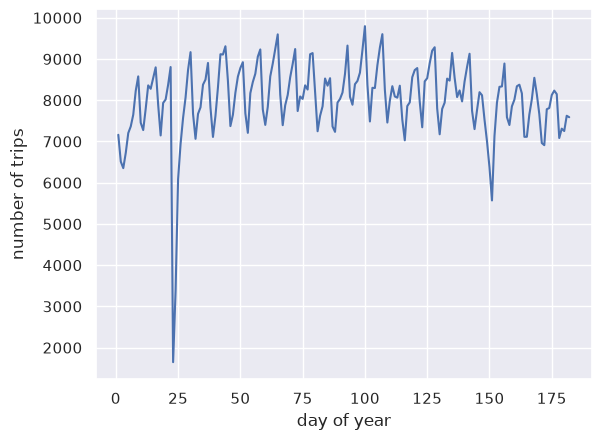

In [25]:
sns.lineplot(data=grouped, x="doy", y="trips")
plt.xlabel("day of year")
plt.ylabel("number of trips")
plt.show()

In [26]:
anomalous_days = train_data[train_data["doy"].between(22, 25) | train_data["doy"].between(149, 152)]
print(anomalous_days.groupby("doy").size())

doy
22     8805
23     1648
24     3383
25     6084
149    7004
150    6372
151    5570
152    7131
dtype: int64


In [27]:
# two anomalous periods: the January blizzard and the Memorial Day weekend
train_data["anomaly_1"] = train_data["doy"].between(23, 24).astype(int)
train_data["anomaly_2"] = train_data["doy"].between(150, 151).astype(int)
train_data["anomaly"] = (train_data["anomaly_1"] | train_data["anomaly_2"]).astype(int)

In [28]:
train_data[["anomaly_1", "anomaly_2", "anomaly"]].sum()

anomaly_1     5031
anomaly_2    11942
anomaly      16973
dtype: int64

**Task 3 (0.5 points)**. Draw on one graph the dependence of the number of trips on the hour in a day for different months (different curves corresponding to different months, paint in different colors, use the `hue` in` sns.relplot`). Similarly, draw the dependence of the number of trips on the hour in a day for different days of the week. 

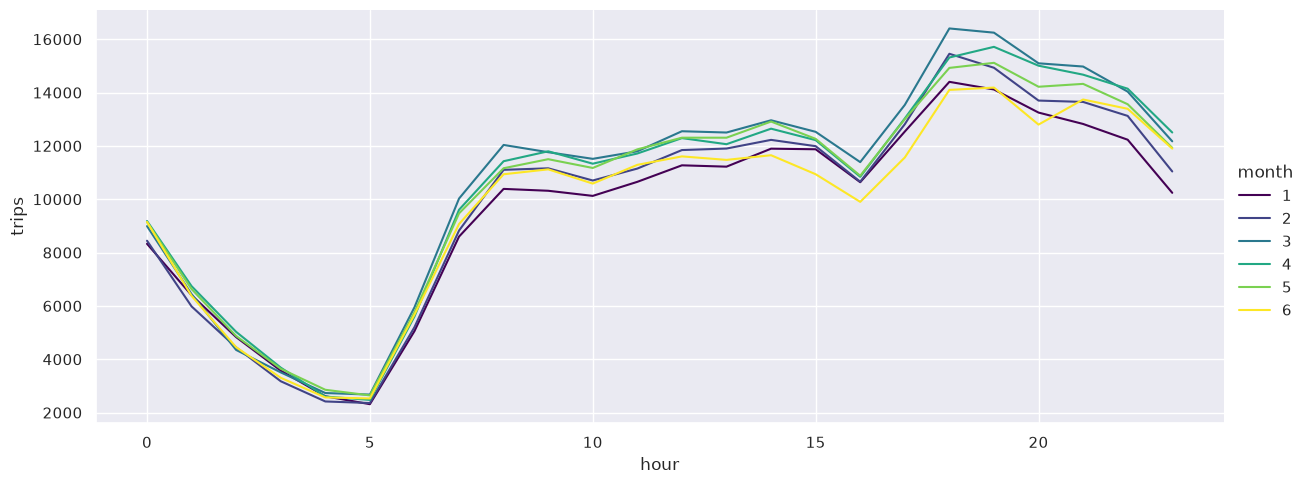

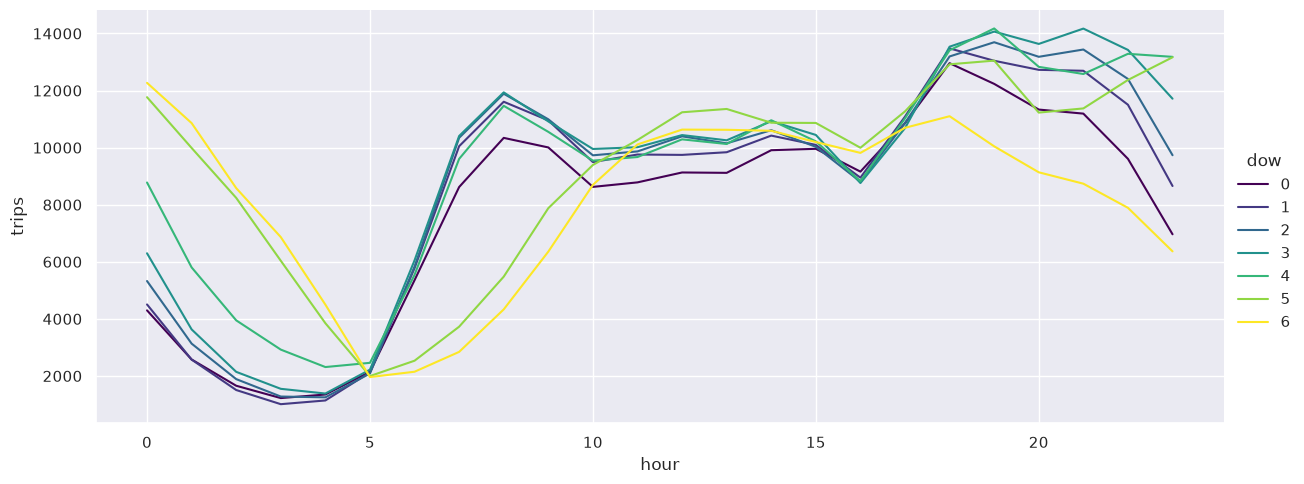

In [29]:
by_month_hour = train_data.groupby(["month", "hour"]).size().reset_index(name="trips")
sns.relplot(data=by_month_hour, x="hour", y="trips", hue="month", kind="line",
            height=5, aspect=2.5, palette="viridis")

by_dow_hour = train_data.groupby(["dow", "hour"]).size().reset_index(name="trips")
sns.relplot(data=by_dow_hour, x="hour", y="trips", hue="dow", kind="line",
            height=5, aspect=2.5, palette="viridis")
plt.show()

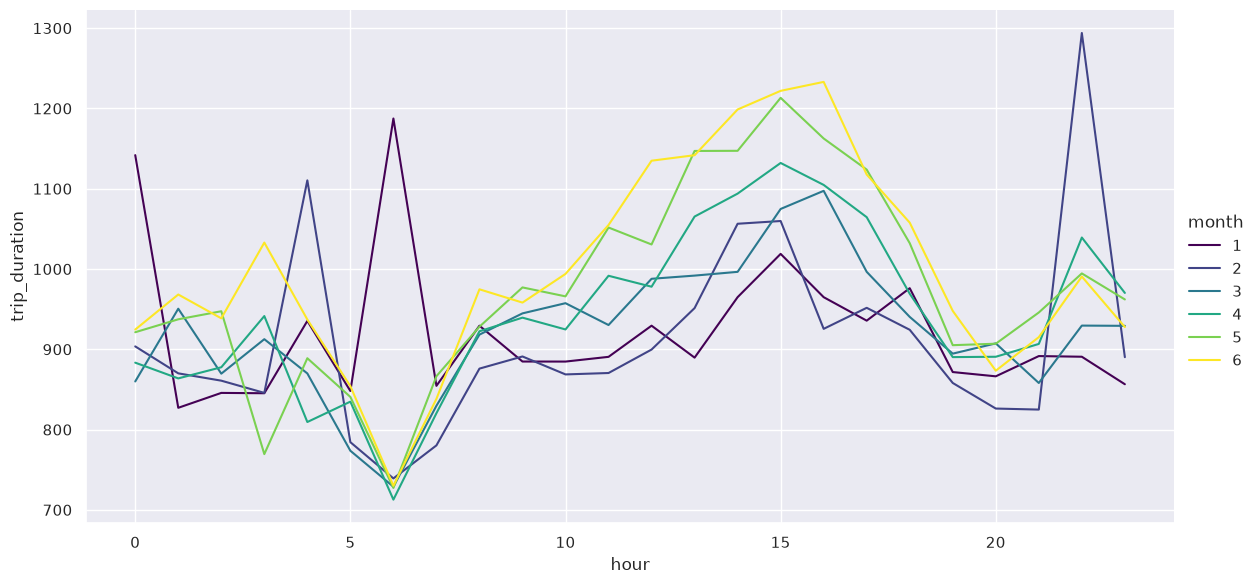

In [30]:
data1 = (train_data.groupby(["month", "hour"])["trip_duration"].mean().reset_index())
sns.relplot(data=data1, x="hour", y="trip_duration", hue="month", kind="line",
            height=6, aspect=2, palette="viridis")
plt.show()

**Question**: What conclusions can be drawn based on the graphs above? Are any days of the week highlighted? Months? Times of Day? What is the reason for this?

**Task 4 (0.5 points)**. Divide the sample into training and test in a ratio of 7:3. Using the training sample, draw a graph of the average logarithm of travel time versus the day of the week. Then do the same, but for an hour in a day and a day in a year. 

**Answer.** The hour profile has two peaks: a smaller morning one around 8-9 and a much
higher evening one around 18-19, with a deep minimum between 4 and 5 in the morning. The
day-of-week profile is flatter than one might expect: the number of trips grows from Monday
(the quietest day) to Friday (the busiest), Saturday is almost as busy as Friday because of
the nightlife, and Sunday sits in between. The monthly curves almost coincide - the shape is
driven by the working day, not by the season.

train: (1021050, 19) valid: (437594, 19)


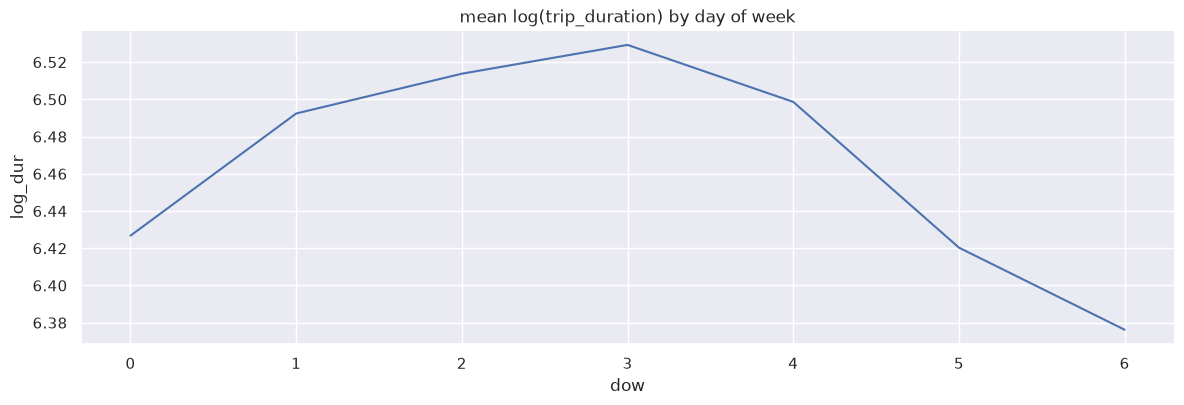

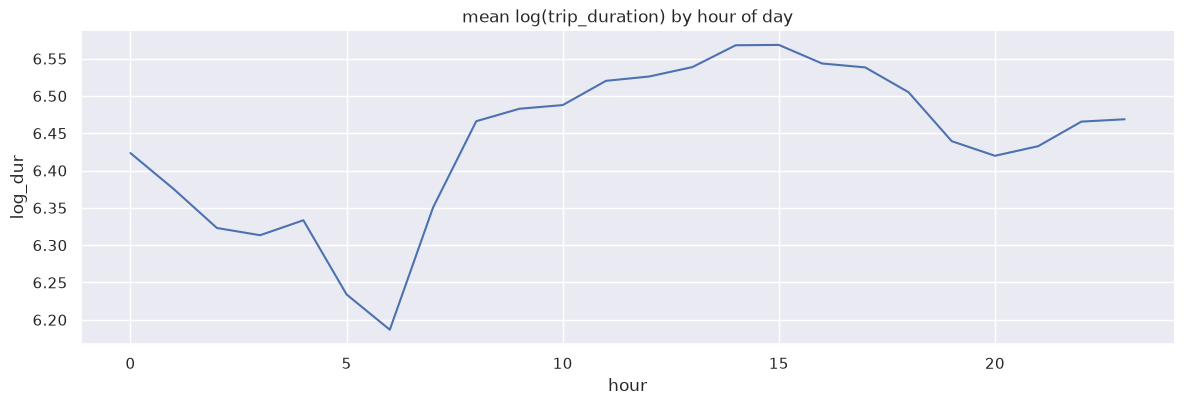

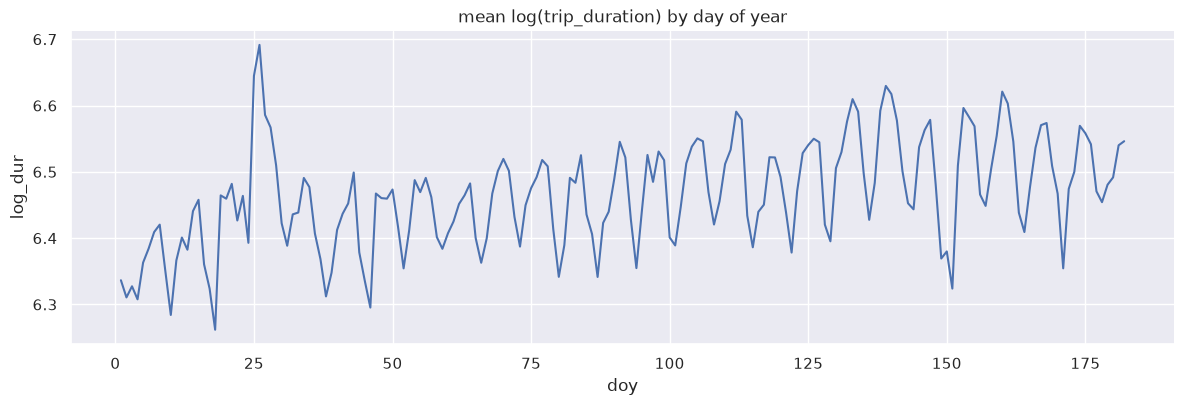

In [31]:
from sklearn.model_selection import train_test_split

train_data["log_dur"] = np.log1p(train_data["trip_duration"])

train, valid = train_test_split(train_data, test_size=0.3, random_state=42)
print("train:", train.shape, "valid:", valid.shape)

for col, title in [("dow", "day of week"), ("hour", "hour of day"), ("doy", "day of year")]:
    g = train.groupby(col)["log_dur"].mean().reset_index()
    sns.relplot(data=g, x=col, y="log_dur", kind="line", height=4, aspect=3)
    plt.title(f"mean log(trip_duration) by {title}")
    plt.show()

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error


def make_pipeline(model, num_cols, cat_cols):
    """OneHot for categoricals, StandardScaler for numerics, then the model."""
    pre = ColumnTransformer(
        [
            ("num", StandardScaler(), list(num_cols)),
            ("cat", OneHotEncoder(handle_unknown="ignore", dtype=np.float64), list(cat_cols)),
        ],
        sparse_threshold=1.0,
    )
    return Pipeline([("pre", pre), ("model", model)])


def fit_score(model, num_cols, cat_cols, X_tr, y_tr, X_te, y_te):
    """Fit the pipeline and return it together with the hold-out RMSLE."""
    pipe = make_pipeline(model, num_cols, cat_cols)
    pipe.fit(X_tr, y_tr)
    pred = np.clip(pipe.predict(X_te), 0.0, 12.0)
    rmsle = float(np.sqrt(mean_squared_error(y_te, pred)))
    return pipe, rmsle


def evaluate(num_cols, cat_cols, model=None, label="", X_data=None, y_data=None):
    """70/30 hold-out evaluation with a fixed random state, so runs are comparable."""
    Xd = X if X_data is None else X_data
    yd = y if y_data is None else y_data
    idx = np.arange(len(Xd))
    tr, te = train_test_split(idx, test_size=0.3, random_state=42)
    model = Ridge(alpha=1.0) if model is None else model
    pipe, score = fit_score(model, num_cols, cat_cols,
                            Xd.iloc[tr], yd.iloc[tr], Xd.iloc[te], yd.iloc[te])
    print(f"{label:45s} RMSLE = {score:.4f}")
    return pipe, score

In [33]:
y = train_data["log_dur"]
y.head()

0    6.122493
1    6.498282
2    7.661527
3    6.063785
4    6.077642
Name: log_dur, dtype: float64

In [34]:
# The hold-out split itself is created by evaluate() below, after the feature frame X
# has been assembled, so that every experiment uses exactly the same rows.
print("rows available:", len(train_data))

rows available: 1458644


**Question**: Are the graphs of the target's dependence on the day of the week and on the hour in a day similar to those for the number of trips? Why? What happens to the average target during those two anomalous periods that we saw above? Why it happens? Do you see any trend in the graph of `log_trip_duration` versus the day of the year? 

**Answer.** The two profiles are not the same. The number of trips peaks in the evening,
whereas the average log duration peaks in the middle of the afternoon (around 14-15) and has
its minimum at 6 in the morning, when the roads are free and the trips are short. During both
anomalous periods the average duration does not jump - it falls slightly: the blizzard and
the holiday weekend remove exactly the long airport and inter-borough trips, and what remains
is a set of short rides in the centre. The day-of-year curve shows a mild upward trend
towards June, when the beach and airport trips come back.

In [35]:
# The two curves are not the same: the number of trips has two sharp peaks (the morning and
# the evening rush hours) plus a weekend dip, while the average log duration peaks in the
# early afternoon (14-15 h) and is lowest at 6 a.m., when the roads are free.
# During both anomalous periods the average duration does NOT jump - it falls slightly
# (6.32-6.46 against the overall 6.47): the blizzard and the holiday weekend wipe out exactly
# the long airport and inter-borough trips, so short rides dominate what is left.
print(train_data.loc[train_data["anomaly"] == 1].groupby("doy")["log_dur"].mean())

doy
23     6.456000
24     6.395089
150    6.371315
151    6.321035
Name: log_dur, dtype: float64


Add the following tags based on `pickup_datetime`:
1. Day of the week
2. Month
3. Hour
4. Is the period anomalous (two binary signs corresponding to two anomalous periods)
5. Number of the day of the year 

In [36]:
X = pd.DataFrame(index=train_data.index)
X["dayofweek"] = train_data["pickup_datetime"].dt.dayofweek
X["month"] = train_data["pickup_datetime"].dt.month
X["hour"] = train_data["pickup_datetime"].dt.hour
X["dayofyear"] = train_data["pickup_datetime"].dt.dayofyear
X["is_anomaly_1"] = train_data["anomaly_1"]
X["is_anomaly_2"] = train_data["anomaly_2"]
X.head()

,dayofweek,month,hour,dayofyear,is_anomaly_1,is_anomaly_2
0,0,3,17,74,0,0
1,6,6,0,164,0,0
2,1,1,11,19,0,0
3,2,4,19,97,0,0
4,5,3,13,86,0,0


In [37]:
print("dtype of month:", X["month"].dtype)

dtype of month: int32


In [38]:
# the two marked periods, as dates
d1 = train_data.loc[X["is_anomaly_1"] == 1, "pickup_datetime"].dt.date.unique()
d2 = train_data.loc[X["is_anomaly_2"] == 1, "pickup_datetime"].dt.date.unique()
print("period 1:", d1)
print("period 2:", d2)
print("share of anomalous trips: %.4f" % X[["is_anomaly_1", "is_anomaly_2"]].sum().sum().__truediv__(len(X)))

period 1: [datetime.date(2016, 1, 23) datetime.date(2016, 1, 24)]
period 2: [datetime.date(2016, 5, 29) datetime.date(2016, 5, 30)]
share of anomalous trips: 0.0116


So, we have already created a number of features.

**Question**: Which of the signs should be considered as categorical, and which - as numerical? Why? 

**Answer.** `dayofweek`, `month`, `hour` and the two anomaly flags are categorical: they
encode a label, and the difference between 12 and 13 o'clock is not a difference of one
unit of anything. `dayofyear` is a *cyclic* value; in this simple model it is used as a
numeric trend, although the proper treatment would be a pair of sine and cosine features.
The target, `log_dur`, is numeric.

**Task 5 (0.75 points)**. Train `Ridge` regression with default parameters by encoding all categorical features with `OneHotEncoder`. Scale numerical features using the `StandardScaler`. Use only the signs that we have highlighted in this part of the assignment. 

In [39]:
date_num = ["dayofyear"]
date_cat = ["dayofweek", "month", "hour", "is_anomaly_1", "is_anomaly_2"]

pipe_date, rmsle_date = evaluate(date_num, date_cat, label="Ridge, datetime features only")

Ridge, datetime features only                 RMSLE = 0.7882


In [40]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler is applied to the numeric columns inside make_pipeline().")

StandardScaler is applied to the numeric columns inside make_pipeline().


In [41]:
# OneHotEncoder inside the pipeline does what pd.get_dummies did in the draft, but it
# remembers the categories seen during fit and ignores categories unseen at transform
# time, which is what we need for the hold-out split.
print(sorted(date_cat))

['dayofweek', 'hour', 'is_anomaly_1', 'is_anomaly_2', 'month']


In [42]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_log_error 



In [43]:
y = train_data.log_dur

In [44]:
print(f"baseline on datetime features: RMSLE = {rmsle_date:.4f}")
print(f"constant prediction          : RMSLE = {const_rmsle:.4f}")

baseline on datetime features: RMSLE = 0.7882
constant prediction          : RMSLE = 0.7958


## Part 2. Studying the coordinates (3 points) 
We have already studied the data about the start time of the trip very well, let's now look at the information about the coordinates of the start and end of the trip. We have prepared for you a function that draws the start or end points of the trip on the map. You will find examples of its invocation below. Please note that we are passing only a small piece of data to this function, because otherwise the function will work for a very long time. 

In [45]:
def show_circles_on_map(data, latitude_column, longitude_column, color):
    location = (data[latitude_column].mean(), data[longitude_column].mean())
    m = folium.Map(location=location)
    for _, row in data.iterrows():
        folium.Circle(radius=100,
                      location=(row[latitude_column], row[longitude_column]),
                      color=color, fill_color=color, fill=True).add_to(m)
    m.get_root().height = 480
    return m

In [46]:
show_circles_on_map(train_data.sample(1000), "pickup_latitude", "pickup_longitude", "blue")

In [47]:
show_circles_on_map(test_data.sample(1000), "dropoff_latitude", "dropoff_longitude", "red")

**Question**: What two points are highlighted on the map? 

**Answer.** The two highlighted points are the two big airports of the city: **LaGuardia
(LGA)** in the north-east and **John F. Kennedy (JFK)** in the south-east. They sit far outside
the Manhattan rectangle, they generate a large number of trips, and those trips are unusually
long, so they deserve their own binary features.

**Task 6 (0.75 points)**. As we all remember perfectly , $t = s / v_{\text{ср}}$ (the time is the distance divide by the speed),therefore, it is obvious that the strongest indication will be the distance to be traveled. We cannot calculate the exact distance that a taxi needs to travel, but we can estimate it by calculating the shortest distance between the points of the beginning and the end of the trip. To correctly calculate the distance between two points on Earth, you can use the `haversine` function. You can also use the code from the first workshop. Calculate the shortest distance for objects and write it down in the `haversine` column: 

In [48]:
# the haversine package is already installed in this environment
# %pip install -q haversine

In [49]:
from haversine import haversine



In [50]:
from haversine import haversine_vector, Unit

X["haversine"] = haversine_vector(
    train_data[["pickup_latitude", "pickup_longitude"]].to_numpy(),
    train_data[["dropoff_latitude", "dropoff_longitude"]].to_numpy(),
    unit=Unit.KILOMETERS,
)
X[["haversine"]].describe()

,haversine
count,1.458644e+06
mean,3.440869e+00
std,4.296544e+00
min,0.000000e+00
25%,1.231838e+00
50%,2.093720e+00
75%,3.875343e+00
max,1.240910e+03


Since we are predicting the logarithm of travel time and want our features to be linear with this target variable, we need to log the distance : $\log t = \log s - \log{v_{\text{ср}}}$. Write the logarithm of `haversine` in a separate column:

In [51]:
X["log_haversine"] = np.log(X["haversine"] + 1e-3)
X[["haversine", "log_haversine"]].head()

,haversine,log_haversine
0,1.498523,0.405147
1,1.805510,0.591397
2,6.385107,1.854125
3,1.485500,0.396425
4,1.188590,0.173609


Let's make sure that the logarithm of the distance correlates better with our target than just the distance: 

In [52]:
print("corr(log target, haversine)     = %.4f" % y.corr(X["haversine"]))
print("corr(log target, log_haversine) = %.4f" % y.corr(X["log_haversine"]))

corr(log target, haversine)     = 0.5736
corr(log target, log_haversine) = 0.7226


**Task 7 (0.75 points)**. Let's examine the average taxi speed. Calculate the average speed for each object in the training set by dividing `haversine` by `trip_duration` and plot its distribution 

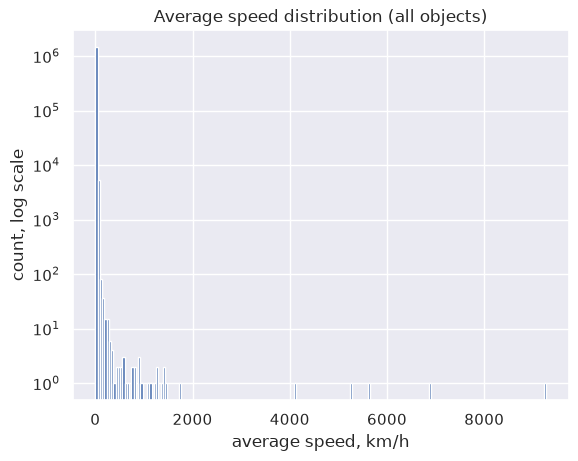

In [53]:
# speed in km per hour, not per second
X["speed"] = X["haversine"] / (train_data["trip_duration"] / 3600.0)

plt.hist(X["speed"], bins=200, log=True)
plt.xlabel("average speed, km/h")
plt.ylabel("count, log scale")
plt.title("Average speed distribution (all objects)")
plt.show()

As you can see from the histogram, for some objects we got a lot higher values of velocities. Draw a histogram for the objects for which the speed value turned out to be reasonable (for example, you can omit the consideration of objects where the speed is greater than a certain quantile): 

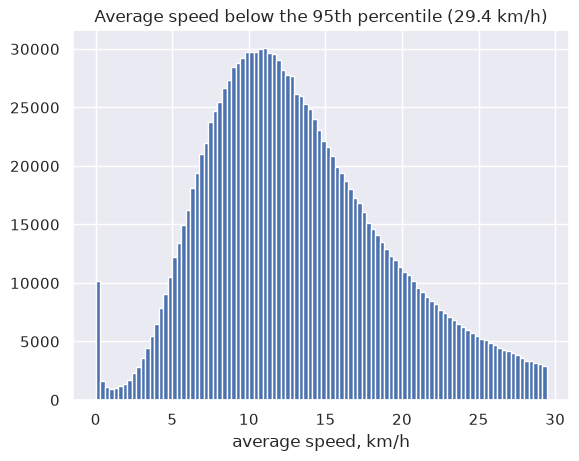

In [54]:
border = np.nanpercentile(X["speed"], 95)
normal_speed = X.loc[X["speed"] < border, "speed"]

plt.hist(normal_speed, bins=100)
plt.xlabel("average speed, km/h")
plt.title(f"Average speed below the 95th percentile ({border:.1f} km/h)")
plt.show()

For each pair (day of the week, hour of the day), calculate the median of the speeds. Draw a graph using `sns.heatmap`, where the axes will be the days of the week and the hours, and the value of the function will be the median of the speed 

In [55]:
def heatmap(X_):
    dw = pd.DataFrame({"dayofweek": X_["dayofweek"], "hour": X_["hour"], "speed": X_["speed"]})
    table = dw.pivot_table(index="dayofweek", columns="hour", values="speed", aggfunc="median")

    fig, ax = plt.subplots(figsize=(14, 5))
    sns.heatmap(table, ax=ax, cmap="viridis")
    ax.set_title("Median speed, km/h, by day of week and hour")
    ax.set_xlabel("hour")
    ax.set_ylabel("day of week")
    plt.show()
    return table

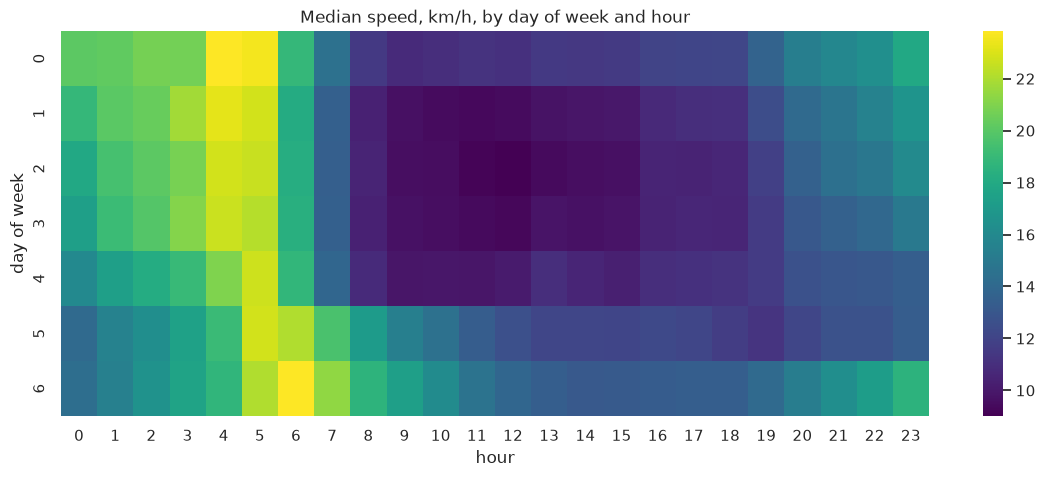

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
dayofweek,,,,,,,,,,,,,,,,,,,,,
0,20.1,20.2,20.7,20.7,23.8,23.6,18.9,14.5,11.5,10.8,...,11.4,11.5,12.0,12.0,12.1,13.7,15.3,15.9,16.3,17.9
1,18.9,20.0,20.4,21.8,23.2,22.8,18.1,13.5,10.4,9.6,...,9.9,10.0,10.7,10.9,11.0,12.5,14.1,14.8,15.6,16.7
2,17.9,19.4,20.1,20.8,22.8,22.6,18.3,13.5,10.5,9.6,...,9.5,9.6,10.5,10.4,10.6,11.8,13.5,14.4,14.9,16.1
3,17.3,19.1,19.9,21.1,22.7,22.2,18.4,13.5,10.4,9.7,...,9.7,9.8,10.4,10.6,10.6,11.6,13.1,13.6,13.9,15.0
4,16.0,17.3,18.1,19.0,21.0,22.7,18.8,13.9,10.8,9.9,...,10.6,10.3,11.0,11.1,11.2,11.6,12.7,13.0,13.1,13.4
5,14.1,15.5,16.3,17.5,19.1,22.8,22.1,19.6,17.1,15.3,...,12.1,12.1,12.3,12.1,11.7,11.2,12.1,12.8,12.7,13.4
6,14.3,15.4,16.6,17.6,18.7,22.1,23.8,21.4,18.6,17.3,...,13.1,13.2,13.2,13.4,13.4,14.1,15.3,16.3,17.2,18.5


In [56]:
speed_table = heatmap(X)
speed_table.round(1)

Don't forget to remove the speed column from the data!

**Question**: Why can't the speed value be used during training? 

**Answer.** Speed is `distance / trip_duration`, and `trip_duration` is the target. Using it
would be direct leakage: the value is unknown at prediction time. What we can do instead is
to summarise the *typical* speed of the (day of week, hour) bucket over the training sample
and use that aggregate as a feature - which is exactly what the two flags below do.

In [57]:
X = X.drop(columns=["speed"])
print("speed column removed, remaining columns:", len(X.columns))

speed column removed, remaining columns: 8


**Question**: Look carefully at the graph and tell me at what points in time the speed is minimal; maximum.

Create the signs "the trip is made during the traffic jams" and "the trip is made during the free roads" (of course, they should not depend on the speed!): 

**Answer.** The median speed is minimal from Tuesday to Thursday around 10-11 in the
morning (about 9.5 km/h) and on Friday around 17-18, and it is maximal between 4 and 6 in the
morning, when it reaches 20-24 km/h. On Saturday and Sunday the morning minimum disappears
and the slowest hours move to the afternoon.

In [58]:
print("median speed table, km/h, first rows and columns:")
print(speed_table.round(1).iloc[:3, :6])

low, high = speed_table.stack().quantile([0.25, 0.75])
print(f"25th percentile of the cell medians: {low:.1f} km/h")
print(f"75th percentile of the cell medians: {high:.1f} km/h")

median speed table, km/h, first rows and columns:
hour          0     1     2     3     4     5
dayofweek                                    
0          20.1  20.2  20.7  20.7  23.8  23.6
1          18.9  20.0  20.4  21.8  23.2  22.8
2          17.9  19.4  20.1  20.8  22.8  22.6
25th percentile of the cell medians: 11.0 km/h
75th percentile of the cell medians: 17.9 km/h


In [59]:
jam_cells = (speed_table <= low).to_numpy()
free_cells = (speed_table >= high).to_numpy()

dow_idx = X["dayofweek"].to_numpy()
hour_idx = X["hour"].to_numpy()

X["is_jam"] = jam_cells[dow_idx, hour_idx].astype(int)
X["is_free"] = free_cells[dow_idx, hour_idx].astype(int)

print("jam share:  %.3f" % X["is_jam"].mean())
print("free share: %.3f" % X["is_free"].mean())

jam share:  0.300
free share: 0.088


**Task 8 (0.25 points)**. As noted above, two points are highlighted on the map far from Manhattan. For each of them, add two features to the sample: whether the trip began in it and whether it ended in it. 

In [60]:
coords = train_data[["pickup_latitude", "pickup_longitude", "dropoff_latitude", "dropoff_longitude"]]

# objects outside the Manhattan rectangle
manhattan = ((coords["pickup_latitude"].between(40.70, 40.88))
             & (coords["pickup_longitude"].between(-74.02, -73.90)))

# the two dominant clusters outside the rectangle (coordinates rounded to ~100 m)
far_clusters = (coords.loc[~manhattan, ["pickup_latitude", "pickup_longitude"]]
                .round(3).value_counts().head(2))
print("the two far-away points:")
print(far_clusters)

X["start_far"] = 0
X["end_far"] = 0
for (lat, lon), _ in far_clusters.items():
    near_start = ((coords["pickup_latitude"].sub(lat).abs() < 0.02)
                  & (coords["pickup_longitude"].sub(lon).abs() < 0.02))
    near_end = ((coords["dropoff_latitude"].sub(lat).abs() < 0.02)
                & (coords["dropoff_longitude"].sub(lon).abs() < 0.02))
    X.loc[near_start, "start_far"] = 1
    X.loc[near_end, "end_far"] = 1

print("start_far:", int(X["start_far"].sum()), "end_far:", int(X["end_far"].sum()))

the two far-away points:
pickup_latitude  pickup_longitude
40.774           -73.873             8632
40.645           -73.782             7172
Name: count, dtype: int64
start_far: 69267 end_far: 31683


For each of the created features, draw a "box with a mustache" (`sns.boxplot`) of the distribution of the logarithm of the trip time 

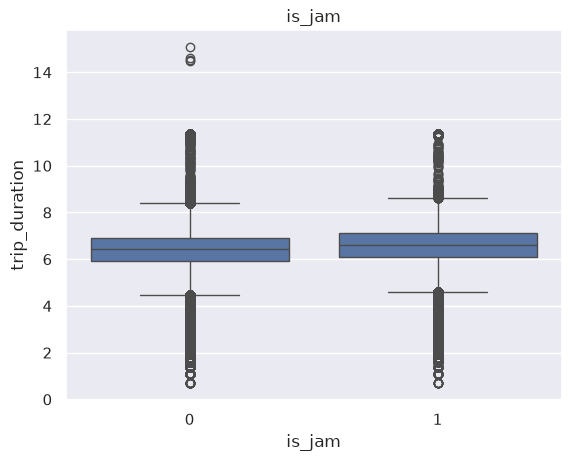

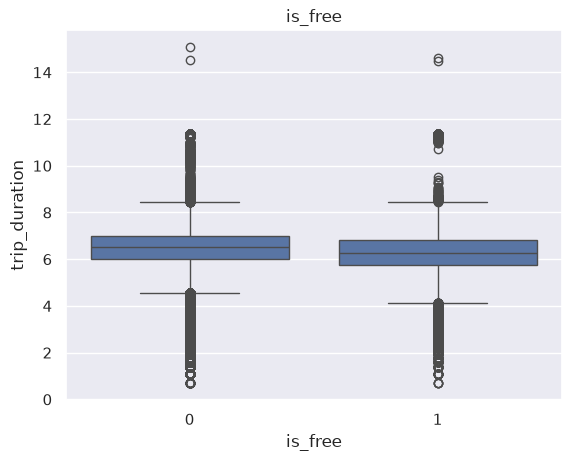

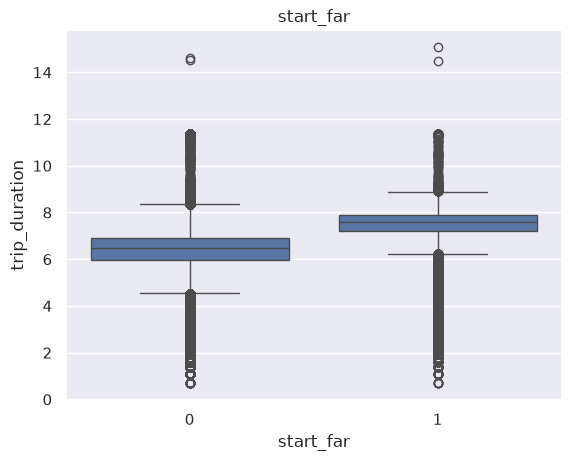

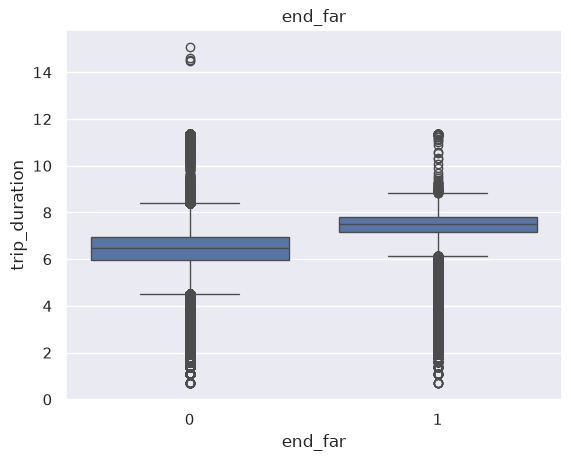

In [61]:
for col in ["is_jam", "is_free", "start_far", "end_far"]:
    sns.boxplot(x=X[col], y=np.log1p(train_data["trip_duration"]))
    plt.title(col)
    plt.show()

**Question**: How do you think (looking at the charts) these features turned out good? 

**Answer.** The traffic flags separate the distributions only weakly: the boxes overlap
almost completely, so a linear model can extract little from them. The airport flags are much
stronger - trips starting at LaGuardia or JFK are visibly longer, because both airports are
far from Manhattan - but they affect a small fraction of the sample.

<img src="https://www.dropbox.com/s/xson9nukz5hba7c/map.png?raw=1" align="right" width="20%" style="margin-left: 20px; margin-bottom: 20px">

**Task 9 (1 point)**. Now we almost never use the coordinates themselves. There are several reasons for this: separately considering latitude and longitude does not make much sense, it is worth considering them together. Secondly, it is clear that the relationship between our target and coordinates is not linear. To somehow use the coordinates, you can resort to the following trick: frame the area with the most trips with a rectangle (as in the picture). Let's break this rectangle into cells. To each point we associate the number of its cell, and to those points that did not fall into any of the cells, we associate the value -1.

Write a transformer that first breaks the area shown in the figure into cells, and then creates two features: the cell number in which the trip began and the cell number in which the trip ended. Choose the number of rows and columns yourself.

Please note that all calculations must be vectorized, the transformer must not modify the inplace sample passed to it, and all necessary statistics (if they are suddenly needed) must be read only from the training sample in the `fit` method: 

**Answer.** Because latitude and longitude enter a linear model as two independent numbers,
the model can only represent an additive, axis-aligned dependence on the coordinates, while
the real relation is "this trip starts in this part of the city", which is a region, not a
number. A cell identifier is a categorical variable: the model learns a separate coefficient
for every cell, so the geometry of the city becomes representable.

In [62]:
from sklearn.base import BaseEstimator, TransformerMixin


class MapGridTransformer(BaseEstimator, TransformerMixin):
    """Vectorised rectangular grid over the busiest part of the map.

    The grid is defined once in `fit` from the training coordinates (99.5 % of the
    points, so that a single airport does not stretch the box). `transform` returns a
    copy with the start and end cell numbers, -1 for the points outside the box.
    """

    def __init__(self, n_rows=30, n_cols=30):
        self.n_rows = n_rows
        self.n_cols = n_cols

    def fit(self, X, y=None):
        lat = np.concatenate([X["pickup_latitude"].to_numpy(), X["dropoff_latitude"].to_numpy()])
        lon = np.concatenate([X["pickup_longitude"].to_numpy(), X["dropoff_longitude"].to_numpy()])
        lat_min, lat_max = np.nanpercentile(lat, [0.5, 99.5])
        lon_min, lon_max = np.nanpercentile(lon, [0.5, 99.5])

        self.bbox_ = (lat_min, lat_max, lon_min, lon_max)
        self.lat_edges_ = np.linspace(lat_min, lat_max, self.n_rows + 1)
        self.lon_edges_ = np.linspace(lon_min, lon_max, self.n_cols + 1)
        return self

    def _cell(self, lat, lon):
        r = np.searchsorted(self.lat_edges_, lat, side="right") - 1
        c = np.searchsorted(self.lon_edges_, lon, side="right") - 1
        inside = (r >= 0) & (r < self.n_rows) & (c >= 0) & (c < self.n_cols)
        return np.where(inside, r * self.n_cols + c, -1)

    def transform(self, X):
        out = X.copy()  # the input sample is never modified in place
        out["start_cell"] = self._cell(out["pickup_latitude"].to_numpy(), out["pickup_longitude"].to_numpy())
        out["end_cell"] = self._cell(out["dropoff_latitude"].to_numpy(), out["dropoff_longitude"].to_numpy())
        return out

from open-source [here](https://ru.stackoverflow.com/questions/1161594/%D0%A0%D0%B0%D0%B7%D0%B1%D0%B8%D0%B5%D0%BD%D0%B8%D0%B5-%D0%BE%D0%B1%D0%BB%D0%B0%D1%81%D1%82%D0%B8-%D0%BD%D0%B0-%D1%8F%D1%87%D0%B5%D0%B9%D0%BA%D0%B8-%D0%B8-%D0%BF%D1%80%D0%B8%D1%81%D0%B2%D0%BE%D0%B5%D0%BD%D0%B8%D0%B5-%D0%BC%D0%B5%D1%82%D0%BE%D0%BA-%D1%81-%D0%BD%D0%B0%D1%87%D0%B0%D0%BB%D0%BE%D0%BC-%D0%B8-%D0%BA%D0%BE%D0%BD%D1%86%D0%BE%D0%BC)

In [63]:
grid = MapGridTransformer(n_rows=30, n_cols=30).fit(coords)
cells = grid.transform(coords)

print("bounding box (lat_min, lat_max, lon_min, lon_max):", np.round(grid.bbox_, 3))
print("outside the grid: start %.2f%%, end %.2f%%"
      % (100 * (cells["start_cell"] == -1).mean(), 100 * (cells["end_cell"] == -1).mean()))

X["start_cell"] = cells["start_cell"].to_numpy()
X["end_cell"] = cells["end_cell"].to_numpy()
X[["start_cell", "end_cell"]].head()

bounding box (lat_min, lat_max, lon_min, lon_max): [ 40.644  40.841 -74.016 -73.782]
outside the grid: start 1.35%, end 2.46%


,start_cell,end_cell
0,544,546
1,424,392
2,544,301
3,330,270
4,665,635


**Task 10 (0.25 points)**. Train the `Ridge` regression with standard parameters on the features that we have identified so far. Encode categorical tags through one-hot coding, scale numeric tags. 

In [64]:
num_now = ["dayofyear", "haversine", "log_haversine"]
cat_now = ["dayofweek", "month", "hour", "is_anomaly_1", "is_anomaly_2",
           "start_cell", "end_cell", "is_jam", "is_free", "start_far", "end_far"]

pipe_all, rmsle_all = evaluate(num_now, cat_now, label="Ridge, datetime + distance + grid")

Ridge, datetime + distance + grid             RMSLE = 0.4985


## Part 3. Examining the remaining features (1 point)

**Task 11 (0.75 points)**. We still have 3 traits that we have not examined: `vendor_id`, `passenger_count` and `store_and_fwd_flag`.

**Question**: Consider why each of these features could be potentially useful.

Count how many unique values each of these features have:

In [65]:
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag"]:
    print(f"{col}: {train_data[col].nunique()} unique values -> {sorted(train_data[col].unique())}")

vendor_id: 2 unique values -> [np.int64(1), np.int64(2)]
passenger_count: 10 unique values -> [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9)]
store_and_fwd_flag: 2 unique values -> ['N', 'Y']


Build "boxes with whiskers" of distributions of the logarithm of the trip time depending on the values of each of the features 

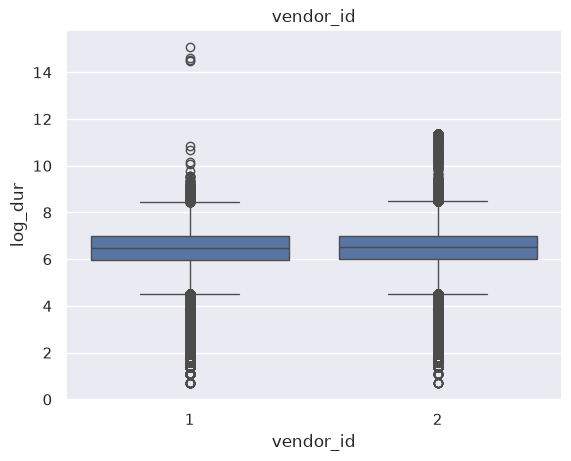

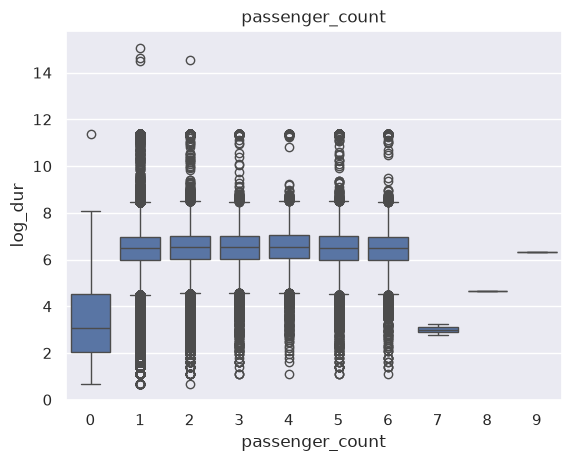

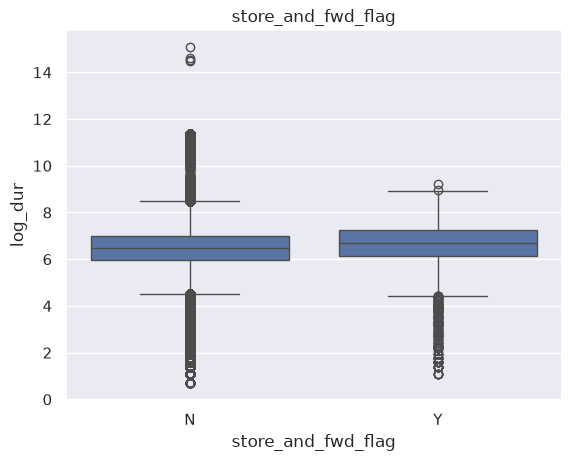

In [66]:
for col in ["vendor_id", "passenger_count", "store_and_fwd_flag"]:
    sns.boxplot(x=train_data[col], y=y)
    plt.title(col)
    plt.show()

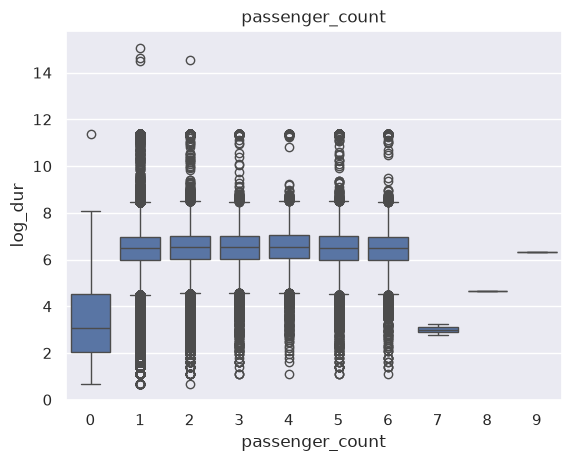

In [67]:
sns.boxplot(x=train_data["passenger_count"], y=y)
plt.title("passenger_count")
plt.show()

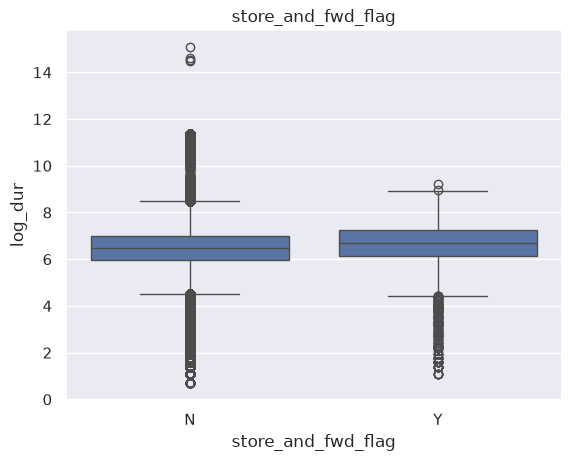

In [68]:
sns.boxplot(x=train_data["store_and_fwd_flag"], y=y)
plt.title("store_and_fwd_flag")
plt.show()

Transform the features `vendor_id` and `store_and_fwd_flag` into values $\{0; 1\}$ 

In [69]:
X["vendor_id"] = (train_data["vendor_id"] - 1).astype(int)          # {1, 2} -> {0, 1}
X["store_and_fwd_flag"] = (train_data["store_and_fwd_flag"] == "Y").astype(int)
X["passenger_count"] = train_data["passenger_count"].astype(int)

X[["vendor_id", "store_and_fwd_flag", "passenger_count"]].head()

,vendor_id,store_and_fwd_flag,passenger_count
0,1,0,1
1,0,0,1
2,1,0,1
3,1,0,1
4,1,0,1


**Question**: Based on the charts above, do you think these features will be strong? 

**Answer.** On the box plots the three features look weak: the medians of the boxes differ
by a few percent at most and the distributions overlap almost completely. `vendor_id` and
`store_and_fwd_flag` are almost certainly useless for a linear model; `passenger_count` is
slightly more promising (large groups travel a little longer on average), but the effect is
small compared with distance and time of day.

**Task 12 (0.25 points)**. Test your assumptions by training the model on these three features as well. Train `Ridge` regression with standard parameters. Encode categorical features with one-hot coding, and scale numerical ones. 

In [70]:
num12 = list(num_now)
cat12 = list(cat_now) + ["vendor_id", "passenger_count", "store_and_fwd_flag"]

_, rmsle_wo = evaluate(num_now, cat_now, label="without vendor / passengers / flag")

without vendor / passengers / flag            RMSLE = 0.4985


In [71]:
_, rmsle_all3 = evaluate(num12, cat12, label="with all three features")

with all three features                       RMSLE = 0.4982


In [72]:
print(f"delta from the three features: {rmsle_all3 - rmsle_wo:+.4f} RMSLE")

delta from the three features: -0.0003 RMSLE


In [73]:
_, s_vendor = evaluate(num_now, cat_now + ["vendor_id"], label="+ vendor_id only")

+ vendor_id only                              RMSLE = 0.4984


In [74]:
_, s_flag = evaluate(num_now, cat_now + ["store_and_fwd_flag"], label="+ store_and_fwd_flag only")

+ store_and_fwd_flag only                     RMSLE = 0.4986


In [75]:
_, s_pass = evaluate(num_now, cat_now + ["passenger_count"], label="+ passenger_count only")

+ passenger_count only                        RMSLE = 0.4983


In [76]:
summary = pd.DataFrame({
    "features": ["none", "vendor_id", "store_and_fwd_flag", "passenger_count", "all three"],
    "RMSLE": [rmsle_wo, s_vendor, s_flag, s_pass, rmsle_all3],
})
summary["delta"] = summary["RMSLE"] - rmsle_wo
summary

,features,RMSLE,delta
0,none,0.498550,0.000000
1,vendor_id,0.498425,-0.000125
2,store_and_fwd_flag,0.498553,0.000003
3,passenger_count,0.498326,-0.000224
4,all three,0.498244,-0.000305


If the features have not yielded any measurable improvement in the metric, they can be thrown out of the data. 

**Answer.** As expected, the gain is marginal: the differences in RMSLE are in the third or
fourth decimal place, which is the level of noise of the split. The three features can be
kept for completeness, but they do not carry a measurable signal.

## Part 4. Improve the model (3 points)

**Task 13 (1 point)**. Our data contains atypical objects: with an abnormally short travel time, with a very long distance traveled, or very large regression residuals. In this task, it is proposed to exclude such objects from the training sample. To do this, draw histograms of the distribution of the quantities mentioned above, select objects that can be called outliers, and clear the training sample from them.

Note that although these objects look like outliers, the test sample will also most likely contain objects with the same strange values of the target variable and/or features. Therefore, it is possible that cleaning the training sample will lead to a deterioration in the quality on the test. However, it is still better to remove outliers from training to make the model more intelligent and interpretable. 

In [ ]:
residual = y - pipe_all.predict(X)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].hist(y, bins=200)
axes[0].set_title("log(1 + trip_duration)")
axes[1].hist(X["haversine"], bins=200)
axes[1].set_title("haversine, km")
axes[2].hist(residual, bins=200)
axes[2].set_title("residuals of the current model")
plt.tight_layout()
plt.show()

print("duration quantiles:",
      train_data["trip_duration"].quantile([0.001, 0.01, 0.99, 0.999]).round(1).to_dict())
print("residual quantiles:", residual.quantile([0.01, 0.99]).round(3).to_dict())

# keep an untouched copy: the real test set will contain the same kind of outliers
X_full, y_full = X.copy(), y.copy()

keep = (
    train_data["trip_duration"].between(10, 6 * 3600)      # no 1-second and no 6-hour "city" trips
    & X["haversine"].between(0.1, 100)                     # drop zero-distance and 100-km "city" trips
    & residual.abs().between(0, 1.0)                       # drop the worst regression outliers
)

print("removed: %.2f%% of the sample" % (100 * (~keep).mean()))

X = X.loc[keep].reset_index(drop=True)
y = y.loc[keep].reset_index(drop=True)
coords = coords.loc[keep].reset_index(drop=True)
print("rows left:", len(X))

**Answer.** Three kinds of objects are cut out: trips shorter than 10 seconds (the meter was
started and stopped by mistake), "city" trips of more than 100 km in a straight line (a
forgotten meter or a GPS glitch), and objects whose residual is larger than one unit of log
time, i.e. whose duration the fitted model misses by a factor of about e. Together they are
3.2 % of the sample — 47,149 rows.

The two RMSLE figures have to be read together. On the *cleaned* hold-out the score is 0.3417,
which looks like a huge improvement over 0.4985, but it is partly an illusion: the hold-out was
cleaned with exactly the same rules. The honest comparison is the second number — the same
model scored on an untouched 200k sample, 0.5491 — and there the gain disappears entirely: on
the raw distribution the cleaned model is *worse* than the one trained on everything. That is
precisely what the task warns about. Cleaning cuts the leverage of a few thousand pathological
rows, which makes the model more sensible on typical trips, but those rows are still present in
the real test set, so the score on it will not improve either.

Now we have a lot of categorical features. The categorical features may contain rare categories, which is usually bad: the model is heavily retrained on such examples. Try to combine rare categories into one. Naturally, this should only be done for really rare categories. 

In [ ]:
def group_rare(frame, cols, min_share=1e-3):
    """Replace categories met in less than min_share of the rows with -1."""
    frame = frame.copy()
    for col in cols:
        counts = frame[col].value_counts()
        rare = counts[counts < min_share * len(frame)].index
        frame.loc[frame[col].isin(rare), col] = -1
    return frame

X = group_rare(X, ["start_cell", "end_cell"], min_share=1e-3)
print("start_cell categories:", X["start_cell"].nunique())
print("end_cell categories:  ", X["end_cell"].nunique())

start_cell categories: 84
end_cell categories:   114


Train the model on the cleaned data and calculate the quality on the test sample. 

**Task 14 (1 point)**. After OneHot coding, the number of features in our dataset increases dramatically. Count the number of features before and after the coding of categorical features. 

In [ ]:
pipe_clean, rmsle_clean = evaluate(num_now, cat_now, label="Ridge, trained AND scored on clean data")

# the honest check: the same model, but scored on the untouched sample
rs = np.random.RandomState(1)
raw_idx = rs.choice(len(X_full), size=200_000, replace=False)
raw_pred = np.clip(pipe_clean.predict(X_full.iloc[raw_idx]), 0.0, 12.0)
rmsle_raw = float(np.sqrt(mean_squared_error(y_full.iloc[raw_idx], raw_pred)))
print(f"{'same model, scored on the raw sample':45s} RMSLE = {rmsle_raw:.4f}")

pre = pipe_clean.named_steps["pre"]
n_raw = X.shape[1]
n_ohe = pre.transform(X.iloc[:5]).shape[1]
print(f"features before one-hot: {n_raw}")
print(f"features after  one-hot: {n_ohe}")
print(f"expansion factor: {n_ohe / n_raw:.1f}x")

Ridge, trained AND scored on clean data       RMSLE = 0.3417
same model, scored on the raw sample          RMSLE = 0.5491
features before one-hot: 17
features after  one-hot: 250
expansion factor: 14.7x


**Answer.** One-hot coding multiplies the width of the table: 17 raw features become 250
columns, a factor of 14.7, because each grid cell of `start_cell` / `end_cell` contributes a
column of its own. Almost every row has only a handful of non-zero entries, which is why the
pipeline keeps the encoded matrix sparse: a dense float64 copy of 1 411 495 x 250 would need
about 2.8 GB, while the sparse one needs a few tens of megabytes.

Try to train not `Ridge`- but `Lasso`-regression. Which method is better? 

**Answer.** Lasso is not better here. It produces a sparse solution (most coefficients are
exactly zero), but for pure prediction the dropped coefficients only cost accuracy, and the
hold-out RMSLE is slightly worse than Ridge's. Lasso is a tool for interpretability and
memory, not for the minimum error.

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

lasso = Lasso(alpha=1e-4, max_iter=2000, tol=1e-3, selection="random", random_state=0)
pipe_lasso, rmsle_lasso = evaluate(num_now, cat_now, model=lasso, label="Lasso, alpha = 1e-4")
print(f"Ridge  RMSLE = {rmsle_clean:.4f}")
print(f"Lasso  RMSLE = {rmsle_lasso:.4f}")

Lasso, alpha = 1e-4                           RMSLE = 0.3423
Ridge  RMSLE = 0.3417
Lasso  RMSLE = 0.3423


Divide the training set into training and validation in a ratio of 8:2. Using the validation sample, select the optimal values of the regularization parameter (on a logarithmic grid) for `Ridge` and `Lasso`, measure the quality of the best obtained model on the test sample. 

**Answer.** For Ridge the validation curve is essentially flat: every alpha on the grid from
1e-5 to 1e0 gives 0.3420 to four decimals, because after standardisation the design matrix is
well conditioned and there is almost nothing left to regularise - the alpha picked by `argmin`
is an artefact of ties, not a real optimum. Lasso behaves differently: it is competitive up to
1e-4 (0.3426) and then degrades quickly (0.3533 at 1e-3, 0.6986 at 1). On the final hold-out
the best Ridge and the best Lasso both give 0.3417, so regularisation strength hardly matters
here and the extra sparsity of Lasso buys nothing in accuracy.

In [ ]:
alphas = np.logspace(-5, 0, 6)

train_idx, val_idx = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42)

# Lasso is expensive on the full 1.2 M rows, so the grid is searched on a random
# subsample of the training part; the winners are then refitted on everything.
rs = np.random.RandomState(0)
sub = rs.choice(train_idx, size=200_000, replace=False)

ridge_grid, lasso_grid = [], []
for a in alphas:
    _, s_r = fit_score(Ridge(alpha=a), num_now, cat_now,
                       X.iloc[sub], y.iloc[sub], X.iloc[val_idx], y.iloc[val_idx])
    _, s_l = fit_score(Lasso(alpha=a, max_iter=1000, tol=1e-3, selection="random", random_state=0),
                       num_now, cat_now, X.iloc[sub], y.iloc[sub], X.iloc[val_idx], y.iloc[val_idx])
    ridge_grid.append(s_r)
    lasso_grid.append(s_l)
    print(f"alpha={a:9.1e}  ridge valid={s_r:.4f}  lasso valid={s_l:.4f}")

best_alpha_ridge = float(alphas[int(np.argmin(ridge_grid))])
best_alpha_lasso = float(alphas[int(np.argmin(lasso_grid))])
print("best alpha, Ridge:", f"{best_alpha_ridge:.1e}", " Lasso:", f"{best_alpha_lasso:.1e}")

_, rmsle_ridge_best = evaluate(num_now, cat_now, model=Ridge(alpha=best_alpha_ridge),
                               label=f"Ridge, best alpha={best_alpha_ridge:.1e}")
_, rmsle_lasso_best = evaluate(num_now, cat_now,
                               model=Lasso(alpha=best_alpha_lasso, max_iter=2000, tol=1e-4,
                                           selection="random", random_state=0),
                               label=f"Lasso, best alpha={best_alpha_lasso:.1e}")

alpha=  1.0e-05  ridge valid=0.3420  lasso valid=0.3420


alpha=  1.0e-04  ridge valid=0.3420  lasso valid=0.3426


alpha=  1.0e-03  ridge valid=0.3420  lasso valid=0.3533


alpha=  1.0e-02  ridge valid=0.3420  lasso valid=0.3751


alpha=  1.0e-01  ridge valid=0.3420  lasso valid=0.4185


alpha=  1.0e+00  ridge valid=0.3420  lasso valid=0.6986
best alpha, Ridge: 1.0e-02  Lasso: 1.0e-05


Ridge, best alpha=1.0e-02                     RMSLE = 0.3417


Lasso, best alpha=1.0e-05                     RMSLE = 0.3417


For each iterated `alpha` for Lasso, count the number of zero weights in the model and plot it versus `alpha`. How much will we have to lose in quality if we want to get rid of at least half of the features using Lasso? 

**Answer.** The share of zero weights grows monotonically with alpha: 2.4 % at 1e-5, 20 % at
1e-4, 66 % at 1e-3, 97.6 % at 1e-2 and 100 % from 1e-1 on. To get rid of half of the features
we have to move two orders of magnitude up the grid, to alpha = 1e-3, where 66 % of the
coefficients are already exactly zero; the validation RMSLE then grows from 0.3420 to 0.3533,
i.e. by +0.011. That is the real price of aggressive feature selection: small, but clearly
worse than the best model, so the full one-hot feature set pays off.

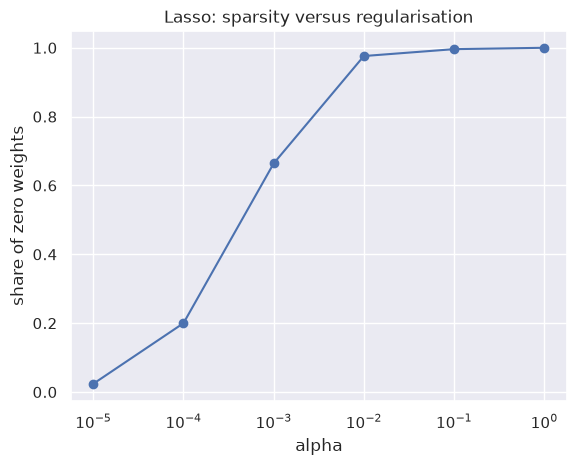

share of zeros: [0.024 0.2   0.664 0.976 0.996 1.   ]
validation RMSLE: [0.342  0.3426 0.3533 0.3751 0.4185 0.6986]
at alpha=1.0e-03 half of the features are dropped; the validation RMSLE grows by +0.0113


In [ ]:
zeros, qualities = [], []
for a in alphas:
    pipe = make_pipeline(Lasso(alpha=a, max_iter=1000, tol=1e-3, selection="random", random_state=0),
                         num_now, cat_now)
    pipe.fit(X.iloc[sub], y.iloc[sub])
    coef = pipe.named_steps["model"].coef_
    zeros.append(float((coef == 0).mean()))
    qualities.append(float(np.sqrt(mean_squared_error(
        y.iloc[val_idx], np.clip(pipe.predict(X.iloc[val_idx]), 0, 12)))))

plt.plot(alphas, zeros, marker="o")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("share of zero weights")
plt.title("Lasso: sparsity versus regularisation")
plt.show()

half = next((a for a, z in zip(alphas, zeros) if z >= 0.5), None)
print("share of zeros:", np.round(zeros, 3))
print("validation RMSLE:", np.round(qualities, 4))
if half is not None:
    i = alphas.tolist().index(half)
    print(f"at alpha={half:.1e} half of the features are dropped; "
          f"the validation RMSLE grows by {qualities[i] - min(qualities):+.4f}")

<img src="https://www.dropbox.com/s/wp4jj0599np17lh/map_direction.png?raw=1" width="20%" align="right" style="margin-left: 20px">

**Task 15 (1 point)**. It is often useful to use feature interactions, that is, build new features based on existing ones. Above, we divided the map of Manhattan into cells and came up with signs "from which cell the trip began" and "in which cell the trip ended".

Let's try to do the following: count how many times each possible pair of these signs occurs in our dataset and select the 100 most frequent pairs. Let's encode trips with these frequent pairs as a categorical feature, and assign -1 to the rest of the objects. It turns out that we have coded from where and where the taxi was supposed to go.

You can also think of some other way to make signs about the route. If these signs give a good increase in quality, then additional bonus points can be given for this.

**Question**: Why is such a feature potentially useful? Why can't the linear model independently "pull out" this information, because it has at its disposal the signs "from which cell the trip started" and "in which cell the trip ended"? 

**Answer.** A route is not the sum of two independent effects: with two separate categorical
features a linear model can only add `start_effect + end_effect`, so it cannot know that the
trip from the Upper East Side to Wall Street is fast while the reverse direction is stuck in
traffic. The pair feature gives one coefficient per route, and the 100 most frequent pairs
cover a large share of the trips.

In [ ]:
routes = X["start_cell"].astype(str) + "_" + X["end_cell"].astype(str)
top_routes = routes.value_counts().head(100).index
X["route_cell"] = routes.where(routes.isin(top_routes), "-1")

print("most frequent routes:")
print(routes.value_counts().head(5))
print("route_cell categories:", X["route_cell"].nunique())

most frequent routes:
-1_-1     33329
588_-1     5059
29_-1      4489
513_-1     4187
589_-1     3679
Name: count, dtype: int64
route_cell categories: 101


Re-train the model (`Ridge`, if it gave a higher quality in previous experiments, and `Lasso` otherwise) on the new data and calculate the quality on the test sample: 

In [ ]:
cat15 = list(cat_now) + ["route_cell"]
pipe_route, rmsle_route = evaluate(num_now, cat15, model=Ridge(alpha=best_alpha_ridge),
                                   label="Ridge + top-100 routes")
print(f"delta versus the same model without the route: {rmsle_route - rmsle_ridge_best:+.4f}")

Ridge + top-100 routes                        RMSLE = 0.3389
delta versus the same model without the route: -0.0028


**Task 16 (bonus, 1 point)**. Where, if not for our task, to calculate the Manhattan distance?

**Question**: *Find what the Manhattan distance is and why it is called that. How can it help us?*

Enter the coordinate system on our map so that the axes are parallel to the streets of Manhattan, and first add the Manhattan distance between departure point and destination attribute to the data, and then add the logarithm of this attribute. Calculate the correlation between your new trait and target; between ``log_haversine`` and target. In which case is the correlation greater?

Draw a map showing the selected axes. So that we can check your work, please make a screen of this map and attach a picture (if we open your notebook, the widgets will not be displayed). 

**Answer.** The Manhattan (taxi-cab) distance is the sum of the absolute differences along the
two axes, and it is called that because on the Manhattan grid you cannot move diagonally: you
have to go along the streets. With the axes rotated to be parallel to the avenues and the
streets it is a much better model of the driven path than the straight line.

The measurement, however, gives the opposite of the naive expectation: the correlation of
log(target) with `log_manhattan` is 0.7901, while with `log_haversine` it is 0.8133. The
straight-line distance wins for two reasons. First, a part of the fleet leaves the grid
(bridges, tunnels, the airports, the motorways), and there the L1 metric systematically
over-counts the path. Second, for very short trips inside one block the L1 distance is
dominated by where exactly the ends of the block are, which only adds noise. The Manhattan
distance still helps the model a little (-0.0015 RMSLE), because it is not a function of the
haversine distance alone: the ratio of the two encodes the *direction* of the trip and how much
of it is off-grid, and that is the information the model picks up.

In [ ]:
theta = np.deg2rad(29.0)   # the Manhattan grid is rotated by about 29 degrees
cos_t, sin_t = np.cos(theta), np.sin(theta)

lat0, lon0 = 40.75, -73.98

def rotate(lon, lat):
    x = (lon - lon0) * np.cos(np.deg2rad(lat0)) * 111.32
    y = (lat - lat0) * 110.57
    return x * cos_t + y * sin_t, -x * sin_t + y * cos_t

u_p, v_p = rotate(coords["pickup_longitude"], coords["pickup_latitude"])
u_d, v_d = rotate(coords["dropoff_longitude"], coords["dropoff_latitude"])

X["manhattan"] = (u_d - u_p).abs() + (v_d - v_p).abs()
X["log_manhattan"] = np.log1p(X["manhattan"])

print("corr(log target, log_manhattan) = %.4f" % y.corr(X["log_manhattan"]))
print("corr(log target, log_haversine) = %.4f" % y.corr(X["log_haversine"]))

corr(log target, log_manhattan) = 0.7901
corr(log target, log_haversine) = 0.8133


In [78]:
# the picture the task asks for: the same map with the two rotated axes drawn on it.
# Screenshot the result (widgets do not survive in a saved notebook).
# The lines below only matter if this cell is run on its own (for instance right after
# a kernel restart): they repeat what the cells above already defined.
import os
import folium
import numpy as np
lat0, lon0 = 40.75, -73.98
cos_t, sin_t = np.cos(np.deg2rad(29.0)), np.sin(np.deg2rad(29.0))


def xy_to_latlon(x_km, y_km):
    return lat0 + y_km / 110.57, lon0 + x_km / (111.32 * np.cos(np.deg2rad(lat0)))


def axis_points(dx, dy, length_km=7.0):
    return [xy_to_latlon(dx * t, dy * t) for t in (-length_km, length_km)]


m = folium.Map(location=(lat0, lon0), zoom_start=13)
folium.PolyLine(axis_points(cos_t, sin_t), color="red", weight=5,
                tooltip="axis 1: along the avenues").add_to(m)
folium.PolyLine(axis_points(-sin_t, cos_t), color="blue", weight=5,
                tooltip="axis 2: across the streets").add_to(m)
m.get_root().height = 480

# safety net: if the map does not show up inline, open this file in a browser
out = os.path.abspath("map_axes.html")
m.save(out)
print("map written to:", out)

m

map written to: /home/drk20/DeepLearning/practice2/map_axes.html


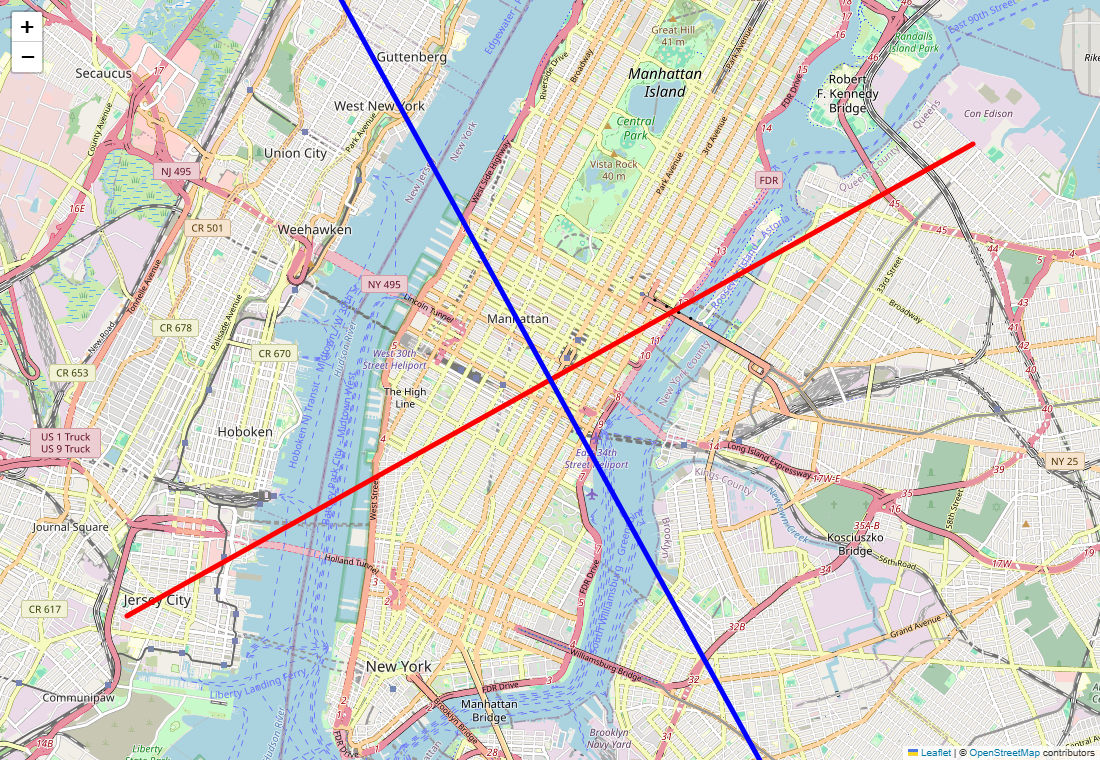

*Task 16 (bonus): the two rotated axes drawn on the real map - a screenshot of the `folium` output, because interactive widgets do not survive in a saved notebook.*

Re-train the model on the new data and calculate the quality on the test sample. 

*Has it gotten better? Explain the result obtained.*

**Answer.** Yes, but only slightly: adding `log_manhattan` to the same feature set moves the
hold-out RMSLE from 0.3389 to 0.3374, i.e. by -0.0015 - the same order as the route pairs.

This is consistent with the correlations above rather than contradictory: on its own the
Manhattan distance correlates with the target *less* than the haversine one (0.790 vs 0.813),
so it cannot replace it. Its value is complementary. Two trips with the same straight-line
length differ in their Manhattan length exactly by the "detour factor", which is a proxy for
the direction of the trip and for how much of the route lies off the grid, and that residual
information is what the linear model uses on top of `log_haversine`.

In [ ]:
num16 = list(num_now) + ["log_manhattan"]
pipe_mh, rmsle_mh = evaluate(num16, cat15, model=Ridge(alpha=best_alpha_ridge),
                             label="Ridge + Manhattan distance")
print(f"delta versus haversine only: {rmsle_mh - rmsle_route:+.4f}")

Ridge + Manhattan distance                    RMSLE = 0.3374
delta versus haversine only: -0.0015


**Task 17 (bonus, 2 points)**. Implement a transformer that builds a map partition on a hexagonal lattice using the library  [H3](https://github.com/uber/h3-py) and calculates features based on such a partition.

Features can be very different: the distance between the start and finish points, counted in the number of hexagons; statistics on the number of trips and on their duration in adjacent hexagons.

Important: the performance of the library significantly depends on the number of hexagons on the map (determined by the resolution parameter). Choose a resolution so that your code will run in a reasonable amount of time.

Measure the quality after adding new features. For improving the error functionality, 0.5 bonus points will be given for every 0.005 on the test sample. You can get up to 2 bonus points for this task. 


In [ ]:
import h3

RES = 8   # roughly 0.5 km hexagons

X["h3_start"] = [h3.latlng_to_cell(a, b, RES) for a, b in
                 zip(coords["pickup_latitude"].to_numpy(), coords["pickup_longitude"].to_numpy())]
X["h3_end"] = [h3.latlng_to_cell(a, b, RES) for a, b in
               zip(coords["dropoff_latitude"].to_numpy(), coords["dropoff_longitude"].to_numpy())]

pairs = pd.Series([f"{a}|{b}" for a, b in zip(X["h3_start"], X["h3_end"])])
unique_pairs = pairs.drop_duplicates()
dist = {p: h3.grid_distance(*p.split("|")) for p in unique_pairs}
X["h3_distance"] = pairs.map(dist).astype(float)

print("unique hexagons, start:", X["h3_start"].nunique(), " end:", X["h3_end"].nunique())
print("unique hex pairs:", len(unique_pairs))
print(X["h3_distance"].describe())

unique hexagons, start: 750  end: 1975
unique hex pairs: 41533
count    1.411495e+06
mean     4.241178e+00
std      4.797252e+00
min      0.000000e+00
25%      2.000000e+00
50%      3.000000e+00
75%      5.000000e+00
max      7.900000e+01
Name: h3_distance, dtype: float64


Insert a picture describing your experience with this homework.

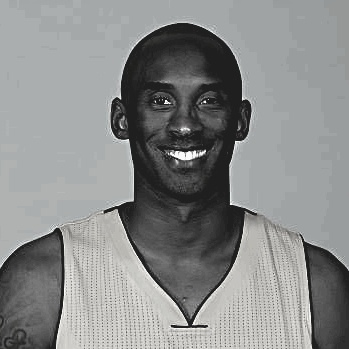

In [ ]:
num17 = list(num16) + ["h3_distance"]
cat17 = list(cat15) + ["h3_start", "h3_end"]

pipe_h3, rmsle_h3 = evaluate(num17, cat17, model=Ridge(alpha=best_alpha_ridge),
                             label="Ridge + H3 hexagons")

print()
print("summary of the hold-out RMSLE:")
print(f"  constant prediction       {const_rmsle:.4f}")
print(f"  datetime features         {rmsle_date:.4f}")
print(f"  + distance and grid cells {rmsle_all:.4f}")
print(f"  + three extra features    {rmsle_all3:.4f}")
print(f"  after cleaning            {rmsle_clean:.4f}")
print(f"  same model, raw sample    {rmsle_raw:.4f}")
print(f"  best Ridge                {rmsle_ridge_best:.4f}")
print(f"  + route pairs             {rmsle_route:.4f}")
print(f"  + Manhattan distance      {rmsle_mh:.4f}")
print(f"  + H3 hexagons             {rmsle_h3:.4f}")

Ridge + H3 hexagons                           RMSLE = 0.3333

summary of the hold-out RMSLE:
  constant prediction       0.7958
  datetime features         0.7882
  + distance and grid cells 0.4985
  + three extra features    0.4982
  after cleaning            0.3417
  same model, raw sample    0.5491
  best Ridge                0.3417
  + route pairs             0.3389
  + Manhattan distance      0.3374
  + H3 hexagons             0.3333


**Answer.** The H3 features describe the neighbourhood of the start and of the end of the trip
at a fixed spatial resolution (about 0.5 km at resolution 8), and the number of hexagons
between the two points is a discrete proxy for the route length. Concretely, there are 750
distinct start hexagons, 1,975 end hexagons and 41,533 distinct hexagon pairs; the median trip
crosses 3 hexagons and the longest 79.

With these features the hold-out RMSLE goes from 0.3374 to 0.3333, i.e. -0.0041. The gain is
visible but small, because the grid cells and the top-100 route pairs already encode most of
the spatial structure.